In [1]:
import os
import pandas as pd
import numpy as np

input_path = 'Z:/DATA/experiment_trackball_Optomotor'

# get list of all locusts tested
dataset=os.listdir(input_path)
dataset
listdaystim=  pd.DataFrame(np.zeros((1000,2)), columns = ['day', 'stimulus'])
c=0
#get all days tested
for locust in dataset:
    locust_directory=input_path + '/' + locust
    file_list = os.listdir(locust_directory)
    for thisDate in file_list:
        if len(thisDate)>6:
            continue
        experiment_directory=locust_directory + '/' + thisDate
        experiment_list=os.listdir(experiment_directory)
        for thisexp in experiment_list:
            listdaystim.loc[c, 'day']= thisDate
            listdaystim.loc[c, 'stimulus']=thisexp
            c=c+1
#get all day-stimulus combinations

In [2]:
grating_days=listdaystim.loc[listdaystim.stimulus=='gratings', 'day'].unique()
dots_days=listdaystim.loc[listdaystim.stimulus=='dots', 'day'].unique()
density_days = listdaystim.loc[listdaystim.stimulus=='densities', 'day'].unique()
splitscreen_day =listdaystim.loc[listdaystim.stimulus=='splitscreen', 'day'].unique()
splitforward_days =listdaystim.loc[listdaystim.stimulus=='splitforward', 'day'].unique()
splitfront_days = listdaystim.loc[listdaystim.stimulus=='splitfront', 'day'].unique()


In [124]:
dots_days

array(['220728', '220803', '220811', '220813', '220814', '220815',
       '220816', '220817', '221106'], dtype=object)

In [3]:
import os
#import argparse
#def create_data_list(input_path, exp_name, exp_date):
data_list=[]
input_path = 'Z:/DATA/experiment_trackball_Optomotor'
dataset=os.listdir(input_path)
exp_date=density_days
exp_name='densities'
for locust in dataset:
    locust_directory=input_path + '/' + locust
    file_list = os.listdir(locust_directory)
    for thisDate in file_list:
        if thisDate in exp_date:
            experiment_directory=locust_directory + '/' + thisDate
            experiment_list=os.listdir(experiment_directory)
            for thisExperiment in experiment_list:
                if thisExperiment in exp_name:
                    data_list.append(experiment_directory + '/' + exp_name)
data_list


['Z:/DATA/experiment_trackball_Optomotor/L22036/220819/densities',
 'Z:/DATA/experiment_trackball_Optomotor/L22037/220819/densities',
 'Z:/DATA/experiment_trackball_Optomotor/L22038/220819/densities',
 'Z:/DATA/experiment_trackball_Optomotor/L22039/220819/densities',
 'Z:/DATA/experiment_trackball_Optomotor/L22040/220822/densities',
 'Z:/DATA/experiment_trackball_Optomotor/L22041/220822/densities',
 'Z:/DATA/experiment_trackball_Optomotor/L22042/220823/densities',
 'Z:/DATA/experiment_trackball_Optomotor/L22043/220823/densities',
 'Z:/DATA/experiment_trackball_Optomotor/L22044/220823/densities',
 'Z:/DATA/experiment_trackball_Optomotor/L22045/220823/densities',
 'Z:/DATA/experiment_trackball_Optomotor/L22046/220823/densities',
 'Z:/DATA/experiment_trackball_Optomotor/L22047/220823/densities',
 'Z:/DATA/experiment_trackball_Optomotor/L22048/220823/densities',
 'Z:/DATA/experiment_trackball_Optomotor/L22049/220824/densities',
 'Z:/DATA/experiment_trackball_Optomotor/L22050/220824/densiti

In [148]:
##The meta information of the stimulus is now included in each cell when the stimulus is delivered
##They are saved as stim_variable object.
##For gratings: it only includs temporal frequency at the moment 2022 sep 6th
##For sweeploom: it includs the initial and ending size; initial and ending position, by this order 
##For sweeploom: it includs stimid, size, Colour1, numDots1, Contrast1, VelX1, Coherence1 by this order 
import os, fnmatch
import pandas as pd
import numpy as np
import re
import math

overwrite_file=False
save_file=True
csv_pattern='trial_*.csv'
dat_pattern='*.dat'    
track_ball_radius=4
frame_rate=144
if exp_name== 'splitcohdens' or exp_name== 'splitforward'or exp_name=='testlinks' or exp_name == 'testrechts' or exp_name=='splitlongfront' or exp_name=='splitscreen' or exp_name == 'splitcoh':
    stim_duration = 120 # in sec
    grey_duration = 0

elif exp_name== 'gratings' or exp_name=='dots' or exp_name =='densities':
    stim_duration= 25
    grey_duration= 5
    
for thisDir in data_list:
    animal_name =thisDir.split('/')[3]
    # list up the files in the dir
    file = os.listdir(thisDir)
    # look for files that matches the pattern
    csv_file= fnmatch.filter(file, csv_pattern)  
    dat_file= fnmatch.filter(file, dat_pattern)
    csv_file_directory= os.path.join(thisDir + '/' ,csv_file[0])
    dat_file_directory= os.path.join(thisDir + '/' ,dat_file[0])
    stim_info = pd.read_csv(csv_file_directory)
    
    stim_info=stim_info.dropna(0)
    stim_info=stim_info.reset_index()
    stim_info.Timestamp=stim_info.Timestamp.astype('int')
    
    if stim_info.size == 0:
        print(thisDir + ' has no stim_info: skipped')
        continue
        
#     if exp_name == 'splitscreen':
#         stim_info = stim_info.iloc[::2,:]
#         stim_info=stim_info.reset_index()
    stim_variable=[]
    stimulus_timestamp=[]
    if exp_name == 'gratings':
        for row in range(0, len(stim_info)):
        #delete the bracket in current speed and save it as integer in new list
            stim_variable.append(int(stim_info.loc[row, 'Frame'].replace('(', '')))
        # combine the last two values into the timestamp (were divided into 2 columns cause german computer
        # used comma as decimal seperator and save timestamp as float in new file
            if isinstance(stim_info.loc[row, 'Value'], float):
                timestamp = stim_info.loc[row, 'Timestamp']
            else:
                timestamp = str(stim_info.loc[row, 'Timestamp']) + '.' + stim_info.loc[row, 'Value']
            stimulus_timestamp.append(float(timestamp.replace(')', '')))
        stim_variable=np.array(stim_variable).reshape((len(stim_info), -1))

    elif exp_name == 'sweeploom':
        for row in range(0, len(stim_info)):
            stim_variable.append(int(stim_info.iloc[row,2].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,3].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,4].split("=",1)[1]))
            stim_variable.append(int(re.split(r'=|}',stim_info.iloc[row,5])[1]))
            if isinstance(stim_info.loc[row, 'Value'], float):
                timestamp = stim_info.loc[row, 'Timestamp']
            else:
                timestamp = str(stim_info.loc[row, 'Timestamp']) + '.' + stim_info.loc[row, 'Value']
            stimulus_timestamp.append(float(timestamp.replace(')', '')))
        stim_variable=np.array(stim_variable).reshape((len(stim_info), -1))
        #some bugs in the bonsai workflow. Needs to remove the first timestamp and the last row of stim variable here
        stimulus_timestamp.pop(0)
        stim_variable=np.delete(stim_variable, -1, axis=0)
        
    elif exp_name == 'dots' or exp_name == 'densities' :
        for row in range(0, len(stim_info)):
            stim_variable.append(int(stim_info.iloc[row,2].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,4].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,5].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,7].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,11].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,13].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,17].split("=",1)[1]))
            if isinstance(stim_info.loc[row, 'Value'], float):
                timestamp = stim_info.loc[row, 'Timestamp']
            else:
                timestamp = str(stim_info.loc[row, 'Timestamp']) + '.' + stim_info.loc[row, 'Value']
            stimulus_timestamp.append(float(timestamp.replace(')', '')))
        stim_variable=np.array(stim_variable).reshape((len(stim_info), -1))
        
    elif exp_name=='splitscreen':
        for row in range(0, len(stim_info)):
            stim_variable.append(int(stim_info.iloc[row,8].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,9].split("=",1)[1]))

            if isinstance(stim_info.loc[row, 'Value'], float):
                timestamp = stim_info.loc[row, 'Timestamp']
            else:
                timestamp = str(stim_info.loc[row, 'Timestamp']) + '.' + stim_info.loc[row, 'Value']
            stimulus_timestamp.append(float(timestamp.replace(')', '')))
        stim_variable=np.array(stim_variable).reshape((len(stim_info), -1))
        
    elif exp_name== 'splitforward'or exp_name=='testlinks' or exp_name == 'testrechts':
        for row in range(0, len(stim_info)):
            stim_variable.append(int(stim_info.iloc[row,7].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,8].split("=",1)[1]))
            
            if isinstance(stim_info.loc[row, 'Value'], float):
                timestamp = stim_info.loc[row, 'Timestamp']
            else:
                timestamp = str(stim_info.loc[row, 'Timestamp']) + '.' + stim_info.loc[row, 'Value']
            stimulus_timestamp.append(float(timestamp.replace(')', '')))
        stim_variable=np.array(stim_variable).reshape((len(stim_info), -1))  
        
    elif exp_name== 'splitlongfront':
        for row in range(0, len(stim_info)):
            stim_variable.append(int(stim_info.iloc[row,7].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,8].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,13].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,14].split("=",1)[1]))
            
            
            if isinstance(stim_info.loc[row, 'Value'], float):
                timestamp = stim_info.loc[row, 'Timestamp']
            else:
                timestamp = str(stim_info.loc[row, 'Timestamp']) + '.' + stim_info.loc[row, 'Value']
            stimulus_timestamp.append(float(timestamp.replace(')', '')))
        stim_variable=np.array(stim_variable).reshape((len(stim_info), -1))
        
    elif exp_name== 'splitcohdens':
        for row in range(0, len(stim_info)):
            stim_variable.append(int(stim_info.iloc[row,7].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,8].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,13].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,14].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,17].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,18].split("=",1)[1].replace('}', '')))
            
            if isinstance(stim_info.loc[row, 'Value'], float):
                timestamp = stim_info.loc[row, 'Timestamp']
            else:
                timestamp = str(stim_info.loc[row, 'Timestamp']) + '.' + stim_info.loc[row, 'Value']
            stimulus_timestamp.append(float(timestamp.replace(')', '')))
        stim_variable=np.array(stim_variable).reshape((len(stim_info), -1))
        
    elif exp_name=='splitcoh':
        for row in range(0, len(stim_info)):
            stim_variable.append(int(stim_info.iloc[row,17].split("=",1)[1]))
            stim_variable.append(int(stim_info.iloc[row,18].split("=",1)[1].replace('}', '')))

            if isinstance(stim_info.loc[row, 'Value'], float):
                timestamp = stim_info.loc[row, 'Timestamp']
            else:
                timestamp = str(stim_info.loc[row, 'Timestamp']) + '.' + stim_info.loc[row, 'Value']
            stimulus_timestamp.append(float(timestamp.replace(')', '')))
        stim_variable=np.array(stim_variable).reshape((len(stim_info), -1))
    else:
        warnings.warn('stimulus paradigm can not be recognised')

    ## load dat file
    ## fictrac title is here 'frame counter', 'delta rotation vector cam x', 'delta rotation vector cam y', \
    ##'delta rotation vector cam z', 'delta rotation error score', 'delta rotation vector lab x', \
    ##'delta rotation vector lab y', 'delta rotation vector lab z', 'absolute rotation vector cam x',\
    ##'absolute rotation vector cam y', 'absolute rotation vector cam z', \
    ##'absolute rotation vector lab x', 'absolute rotation vector lab y', \
    ##'absolute rotation vector lab z', 'intergrated x position','intergrated y position', \
    ##'intergrated animal heading', 'animal movement direction', 'animal movement speed', \
    ##'intergrated forward motion','intergrated side motion', 'timestamp', 'sequence counter','delta timestamp', 'alt. timestamp']

    ## load dat file
    raw_data = pd.read_table(dat_file_directory, sep="\s+")

    ## drop some column
    raw_data.drop(raw_data.columns[[0,1,2,3,4,8,9,10,16,17,18,19,20,21,22,23]], axis=1, inplace=True)
    raw_data.columns=['delta rotation vector lab x', 'delta rotation vector lab y', 'delta rotation vector lab z',                       'absolute rotation vector lab x', 'absolute rotation vector lab y', 'absolute rotation vector lab z',                       'intergrated x position','intergrated y position', 'timestamp']
    ## cleaning , and change the data from object to float
    raw_data.iloc[:, :]=raw_data.iloc[:, :].replace({',': ''}, regex= True)
    for ind in range(0, raw_data.shape[1]):
        raw_data.iloc[:, ind]=pd.to_numeric(raw_data.iloc[:, ind]).astype('float32')

    ## adjust the unit of the x, y position
    raw_data.iloc[:, 6]=raw_data.iloc[:, 6]*track_ball_radius
    raw_data.iloc[:, 7]=raw_data.iloc[:, 7]*track_ball_radius
    ## adjust the unit of the z vector based on the target frame rate of fictrac
    raw_data.iloc[:, 2]=raw_data.iloc[:, 2]*frame_rate

    # apply filter to the raw trace
    #curr_data.loc[:, ['x_pos']] = scipy.signal.savgol_filter(curr_data.loc[:, ['x_pos']], 99, 3, axis=0)
    #curr_data.loc[:, ['y_pos']] = scipy.signal.savgol_filter(curr_data.loc[:, ['y_pos']], 99, 3, axis=0)

    # compare the timestamp between event file and dat file
    data_timestamp=raw_data.loc[:, 'timestamp']
    stimulus_timestamp_b=np.tile(stimulus_timestamp,(len(data_timestamp),1))
    data_timestamp_b=np.tile(data_timestamp,(len(stimulus_timestamp),1))
    timestamp_diff= data_timestamp_b > np.transpose(stimulus_timestamp_b)
    stim_onset= np.where(np.roll(timestamp_diff,1,axis=1)!=timestamp_diff)[1][1::2]
    
    if stim_onset.size == 0:
        print(thisDir + 'timestamp matching issue: skipped')
        continue
        
    ### add new column here to store event info
#         raw_data['frame_rate']=frame_rate
#         if isinstance(frame_rate, int):
#             raw_data['frame_rate']=raw_data['frame_rate'].astype('int16')  
#         elif isinstance(frame_rate, int):
#             raw_data['frame_rate']=raw_data['frame_rate'].astype('float16')

    raw_data['stim_duration']=stim_duration
    raw_data['stim_duration']=raw_data['stim_duration'].astype('int8')        
    raw_data['grey_duration']=grey_duration
    if isinstance(grey_duration, int):
        raw_data['grey_duration']=raw_data['grey_duration'].astype('int8') 

    if grey_duration== 0:
        raw_data['stim_onset']=False
        stim_onset = stim_onset + np.ones(np.shape(stim_onset),dtype=int)*int(stim_duration/2)*int(frame_rate)
        raw_data.loc[stim_onset, 'stim_onset']=True
        raw_data['stim_variable']=object
        for ind in range(0, len(stimulus_timestamp)):
            ## use at not loc as the data input is object not int
            raw_data.at[stim_onset[ind], 'stim_variable']=stim_variable[ind,:]
    else:
        raw_data['stim_onset']=False
        raw_data.loc[stim_onset, 'stim_onset']=True
        raw_data['stim_variable']=object
        for ind in range(0, len(stimulus_timestamp)):
            raw_data.at[stim_onset[ind], 'stim_variable']=stim_variable[ind,:]
            
    ### save the curated_database
    if save_file==True:
        database_name='database_curated.pickle'
        database_directory= os.path.join(thisDir,database_name)
        if (overwrite_file ==False) and (os.path.isfile == True):
            continue
        else:
            raw_data.to_pickle(database_directory)
    print(thisDir)

C:\Users\excid\AppData\Local\Temp/ipykernel_19372/3906653141.py:37: FutureWarning: In a future version of pandas all arguments of DataFrame.dropna will be keyword-only
  stim_info=stim_info.dropna(0)


Z:/DATA/experiment_trackball_Optomotor/L22006/220728/dots
Z:/DATA/experiment_trackball_Optomotor/L22007/220728/dots
Z:/DATA/experiment_trackball_Optomotor/L22008/220728/dots
Z:/DATA/experiment_trackball_Optomotor/L22009/220803/dots
Z:/DATA/experiment_trackball_Optomotor/L22010/220803/dots
Z:/DATA/experiment_trackball_Optomotor/L22011/220803/dots
Z:/DATA/experiment_trackball_Optomotor/L22012/220803/dots
Z:/DATA/experiment_trackball_Optomotor/L22013/220811/dots
Z:/DATA/experiment_trackball_Optomotor/L22014/220811/dots
Z:/DATA/experiment_trackball_Optomotor/L22015/220811/dots
Z:/DATA/experiment_trackball_Optomotor/L22016/220813/dots
Z:/DATA/experiment_trackball_Optomotor/L22017/220813/dots
Z:/DATA/experiment_trackball_Optomotor/L22018/220813/dots
Z:/DATA/experiment_trackball_Optomotor/L22018/220814/dots
Z:/DATA/experiment_trackball_Optomotor/L22019/220814/dots
Z:/DATA/experiment_trackball_Optomotor/L22020/220814/dots


In [151]:
raw_data.to_pickle(database_directory)

Z:/DATA/experiment_trackball_Optomotor/L22036/220819/densities


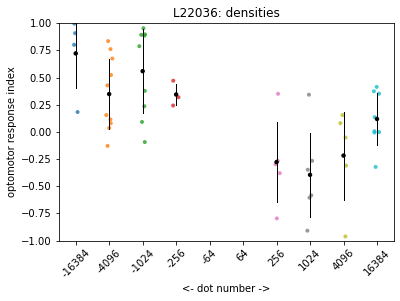

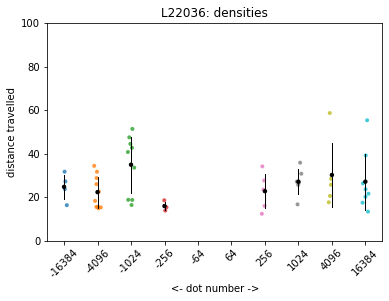

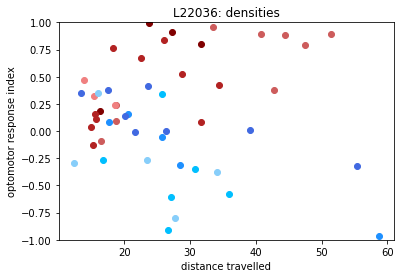

Z:/DATA/experiment_trackball_Optomotor/L22037/220819/densities


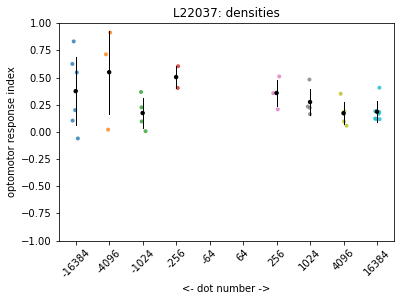

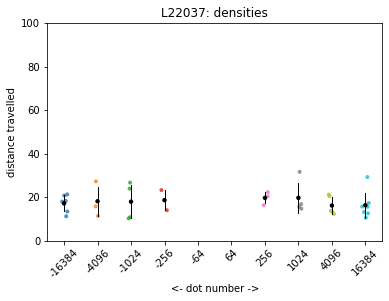

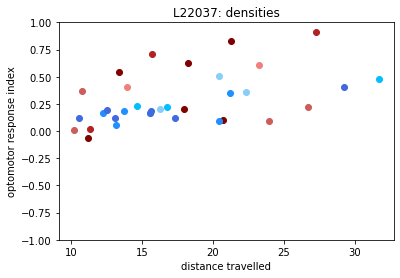

Z:/DATA/experiment_trackball_Optomotor/L22038/220819/densities


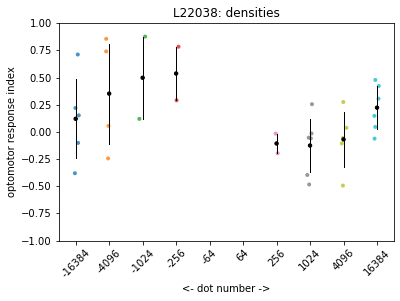

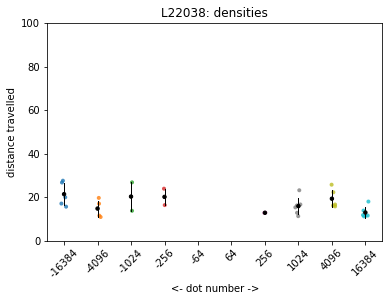

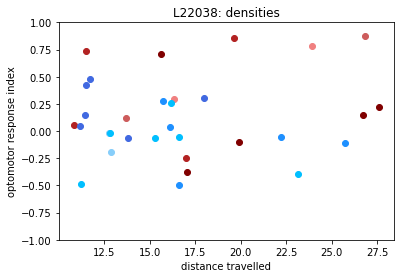

Z:/DATA/experiment_trackball_Optomotor/L22039/220819/densities


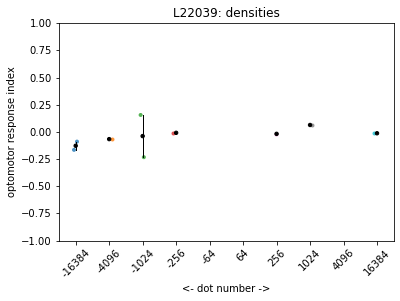

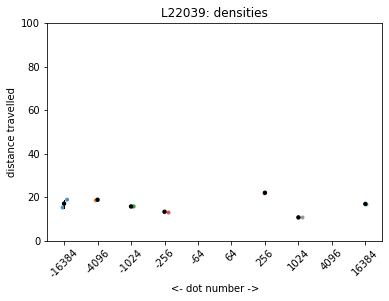

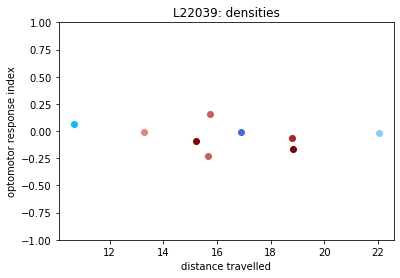

Z:/DATA/experiment_trackball_Optomotor/L22040/220822/densities


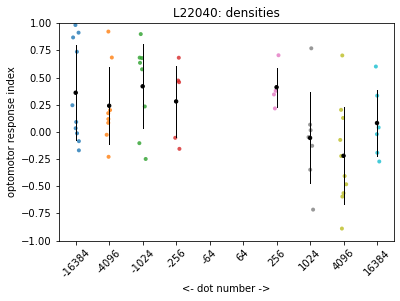

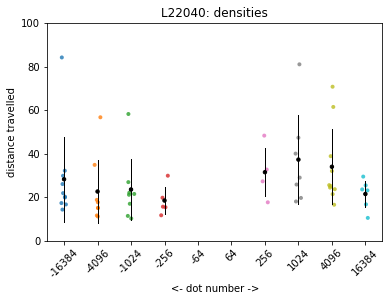

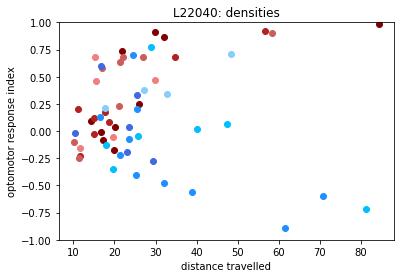

Z:/DATA/experiment_trackball_Optomotor/L22041/220822/densities


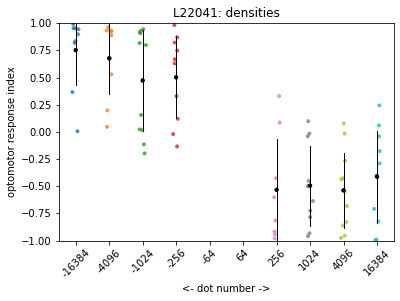

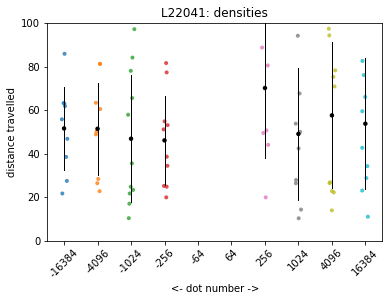

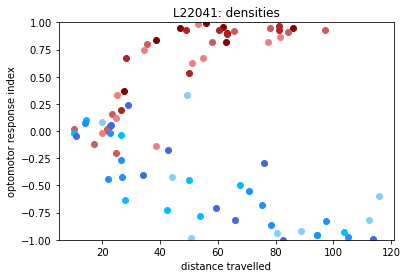

Z:/DATA/experiment_trackball_Optomotor/L22042/220823/densities


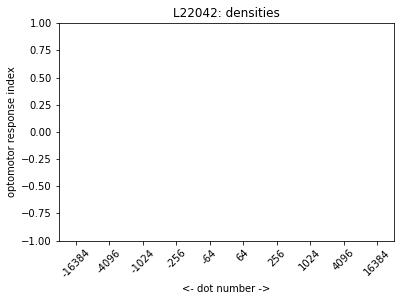

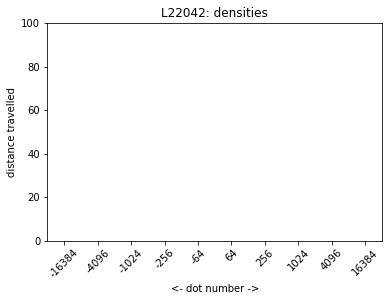

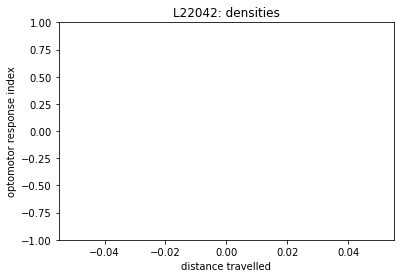

Z:/DATA/experiment_trackball_Optomotor/L22043/220823/densities


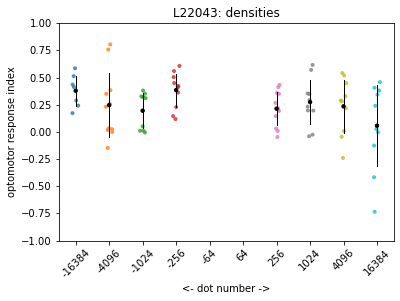

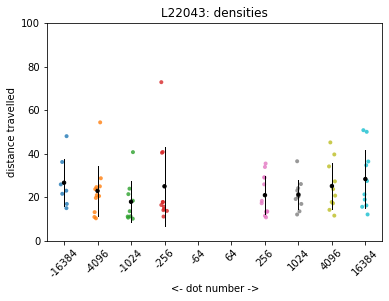

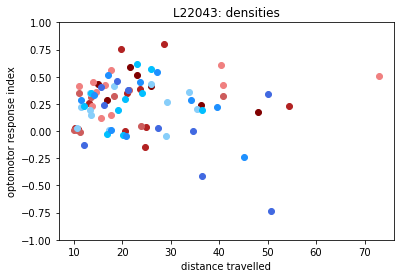

Z:/DATA/experiment_trackball_Optomotor/L22044/220823/densities


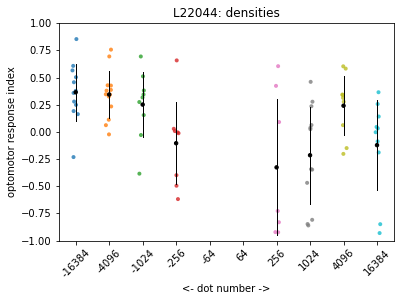

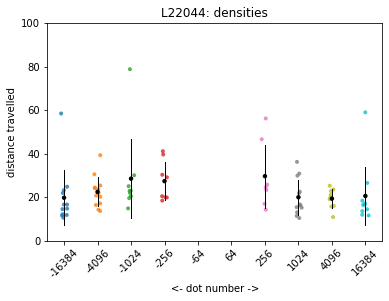

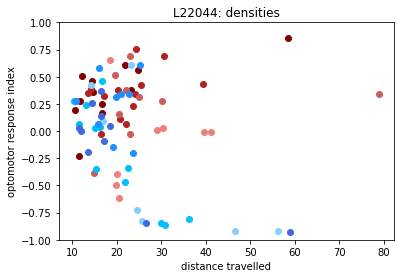

Z:/DATA/experiment_trackball_Optomotor/L22045/220823/densities


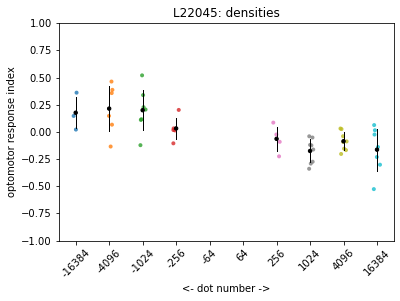

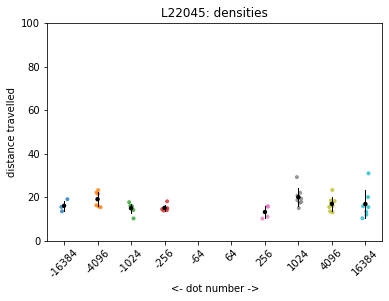

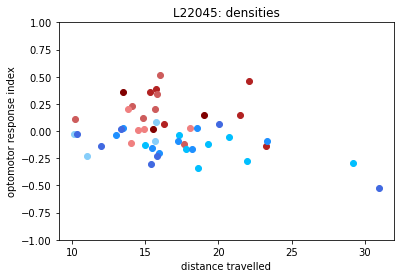

Z:/DATA/experiment_trackball_Optomotor/L22046/220823/densities


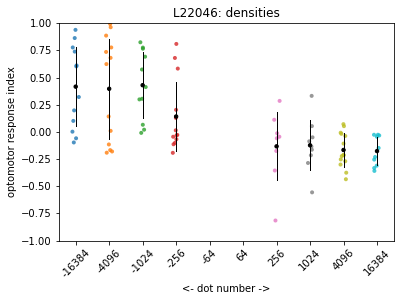

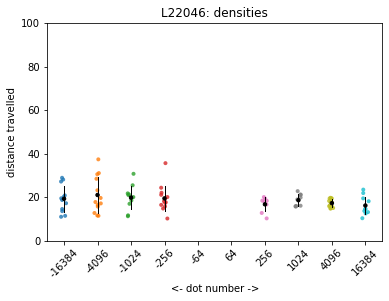

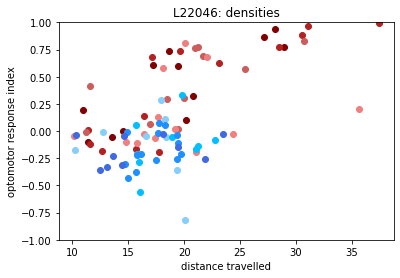

skipped Z:/DATA/experiment_trackball_Optomotor/L22047/220823/densities
skipped Z:/DATA/experiment_trackball_Optomotor/L22048/220823/densities
Z:/DATA/experiment_trackball_Optomotor/L22049/220824/densities


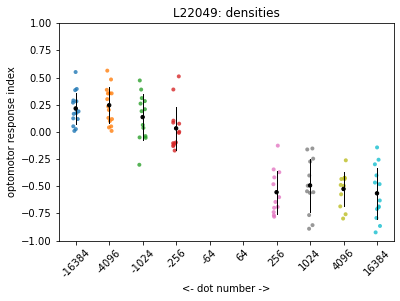

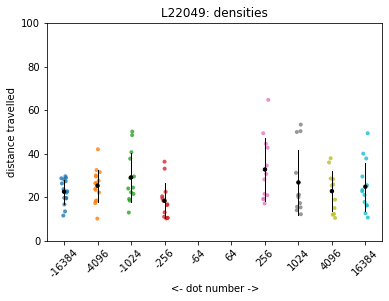

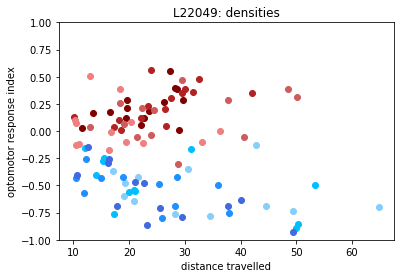

Z:/DATA/experiment_trackball_Optomotor/L22050/220824/densities


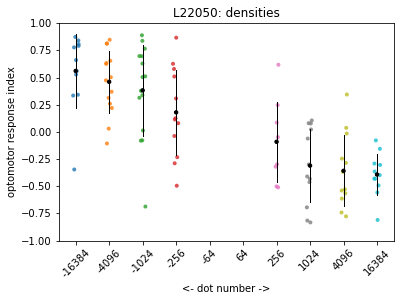

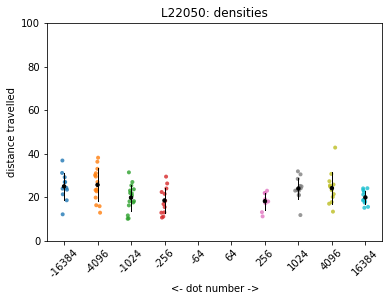

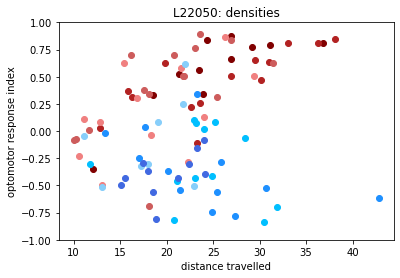

Z:/DATA/experiment_trackball_Optomotor/L22051/220824/densities


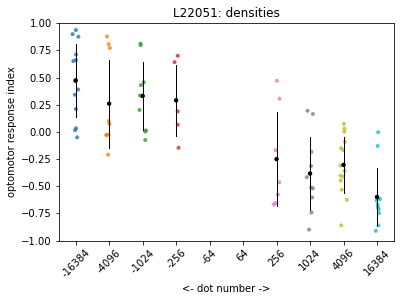

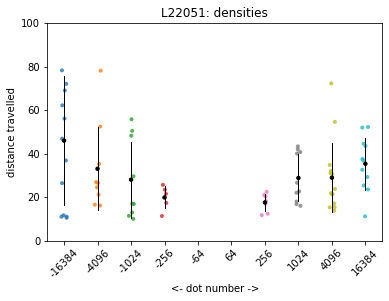

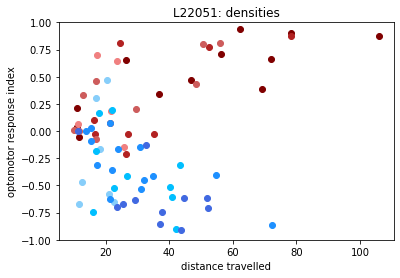

Z:/DATA/experiment_trackball_Optomotor/L22052/220824/densities


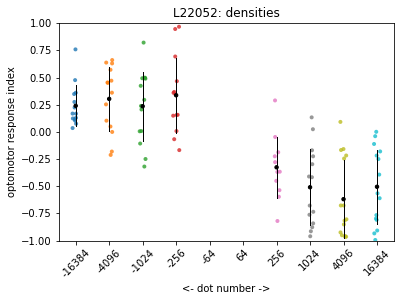

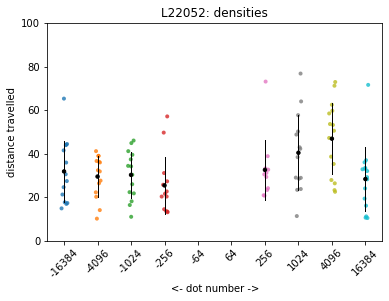

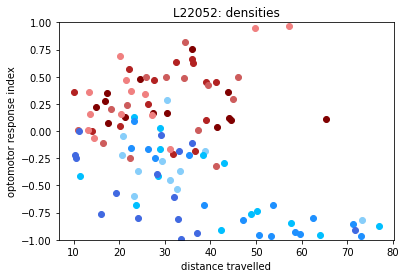

Z:/DATA/experiment_trackball_Optomotor/L22056/220905/densities


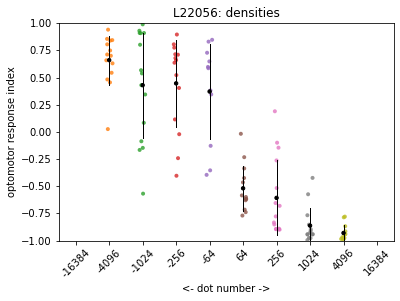

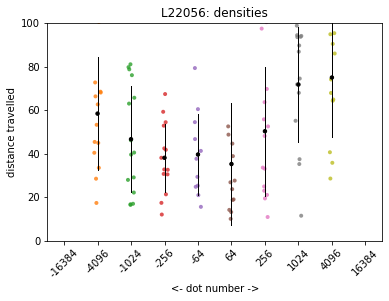

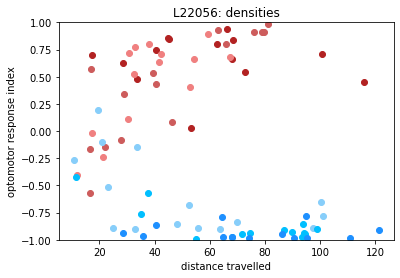

Z:/DATA/experiment_trackball_Optomotor/L22057/220905/densities


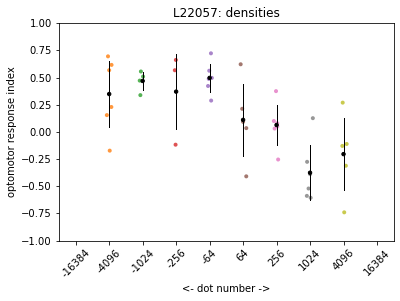

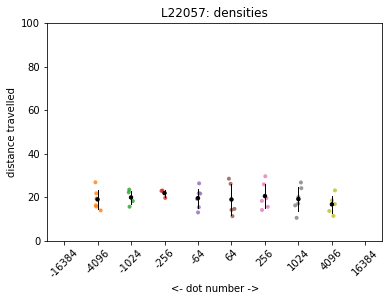

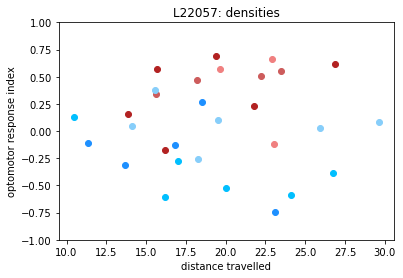

Z:/DATA/experiment_trackball_Optomotor/L22058/220905/densities


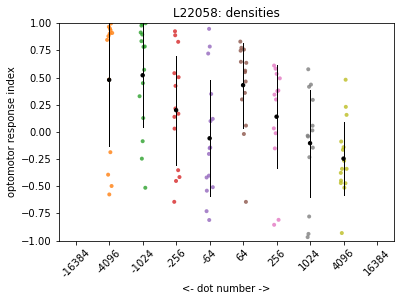

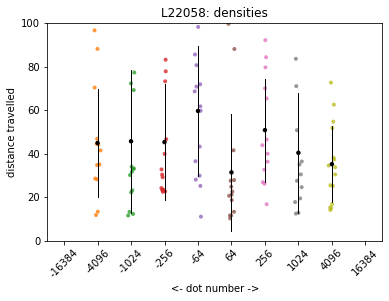

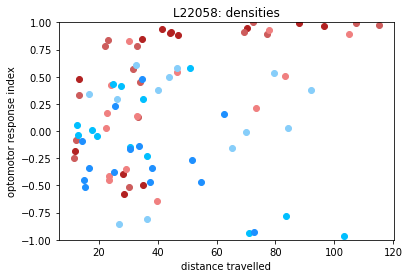

Z:/DATA/experiment_trackball_Optomotor/L22059/220906/densities


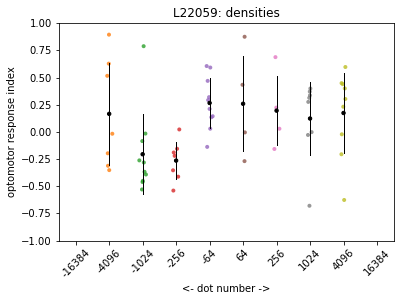

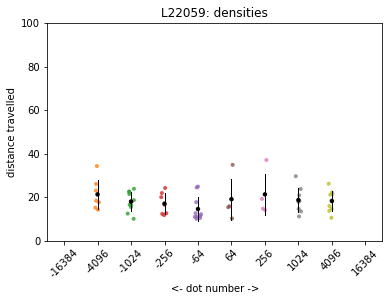

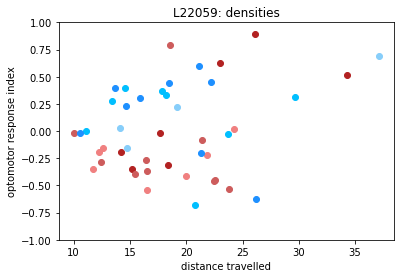

Z:/DATA/experiment_trackball_Optomotor/L22060/220906/densities


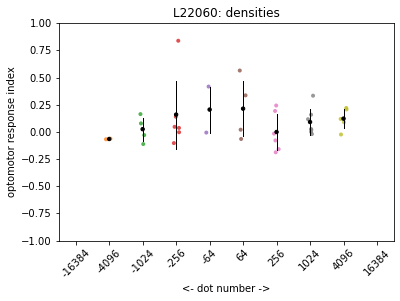

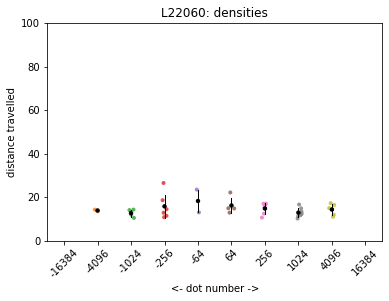

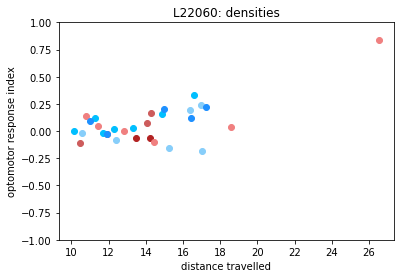

Z:/DATA/experiment_trackball_Optomotor/L22061/220906/densities


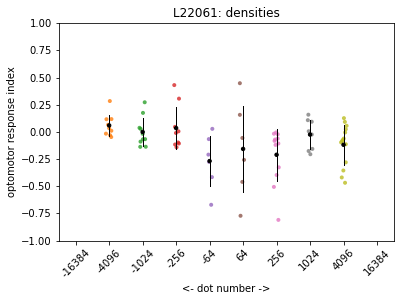

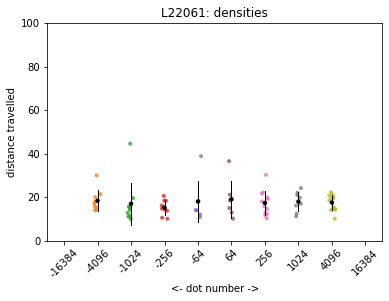

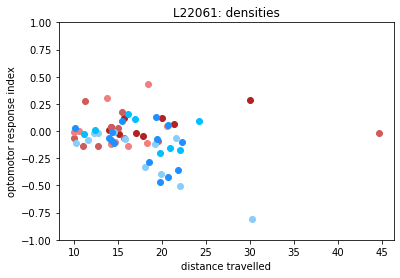

Z:/DATA/experiment_trackball_Optomotor/L22062/220907/densities


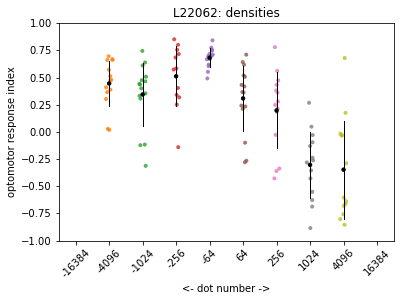

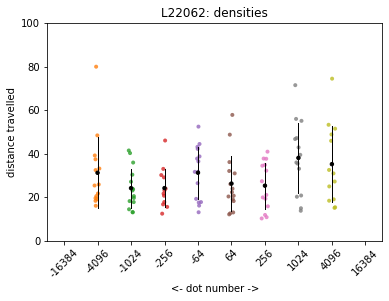

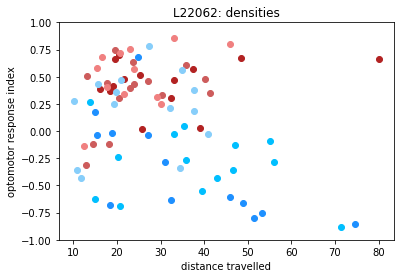

Z:/DATA/experiment_trackball_Optomotor/L22063/220907/densities


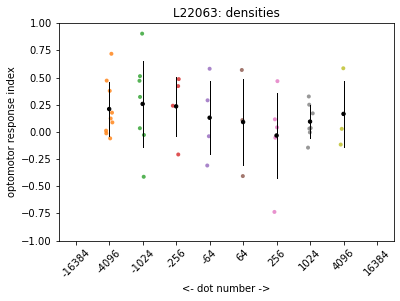

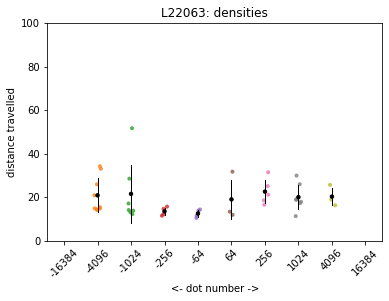

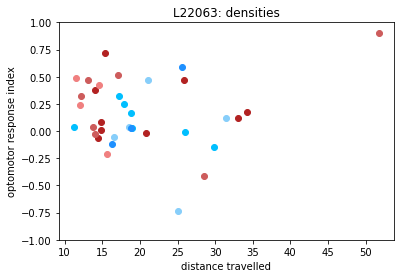

skipped Z:/DATA/experiment_trackball_Optomotor/L22064/220907/densities
Z:/DATA/experiment_trackball_Optomotor/L22065/220907/densities


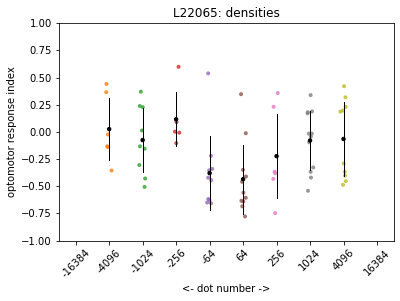

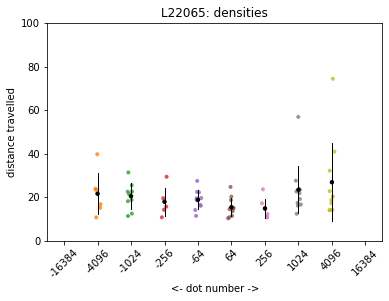

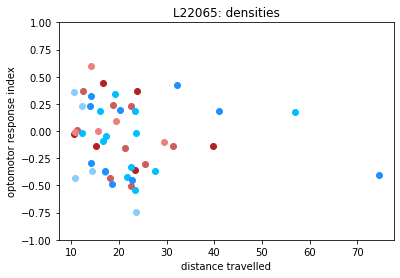

Z:/DATA/experiment_trackball_Optomotor/L22066/220907/densities


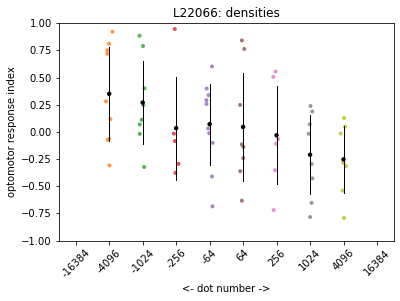

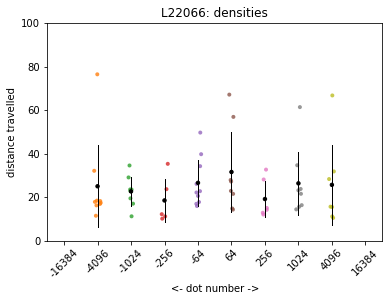

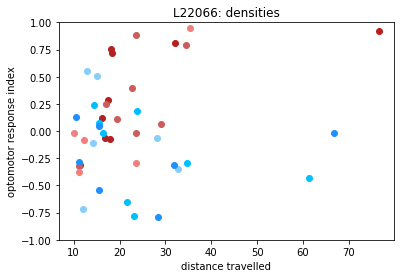

Z:/DATA/experiment_trackball_Optomotor/L22067/220907/densities


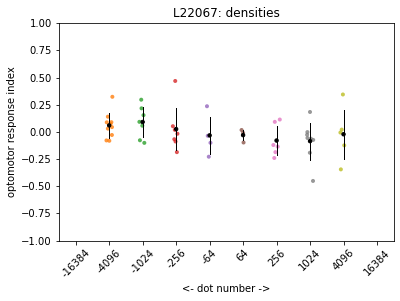

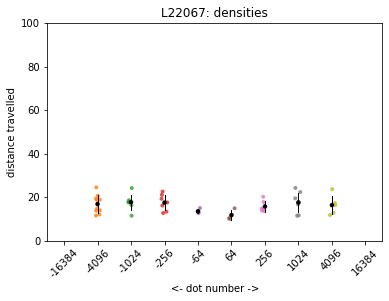

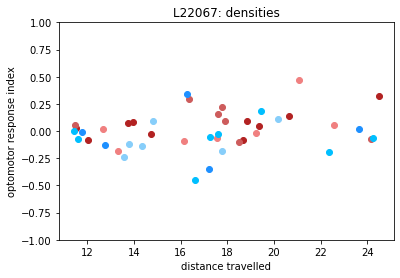

Z:/DATA/experiment_trackball_Optomotor/L22068/220907/densities


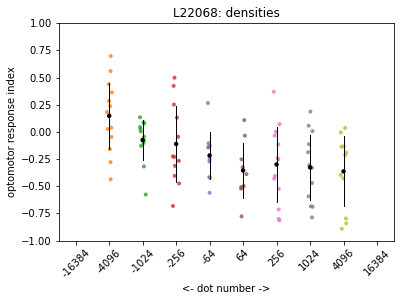

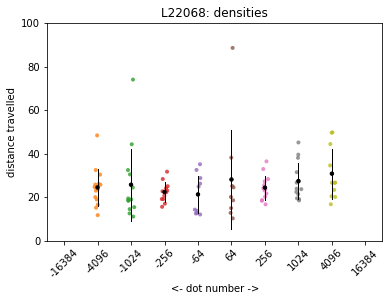

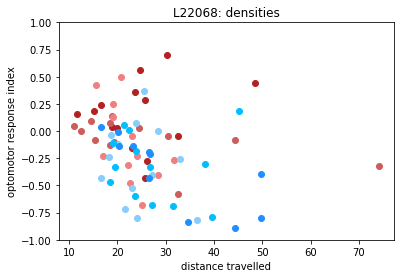

Z:/DATA/experiment_trackball_Optomotor/L22069/220908/densities


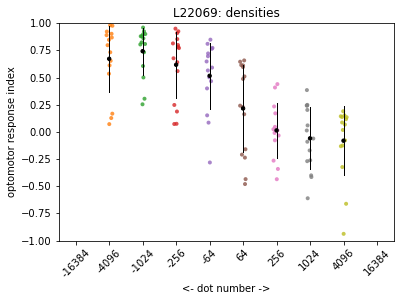

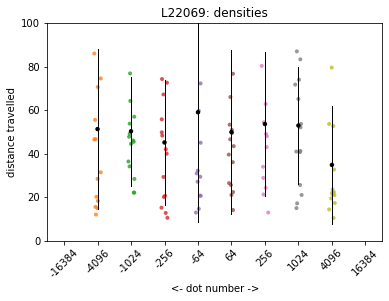

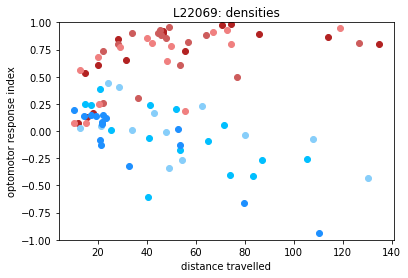

Z:/DATA/experiment_trackball_Optomotor/L22070/220908/densities


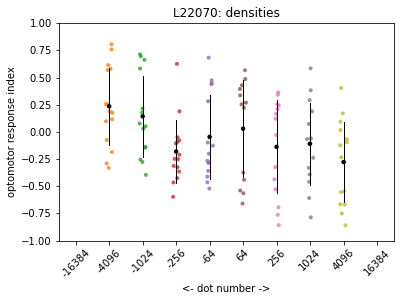

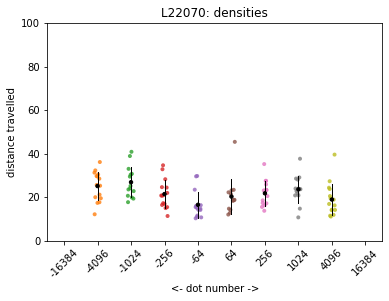

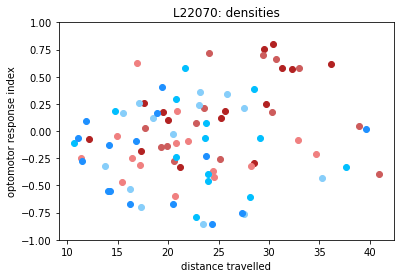

Z:/DATA/experiment_trackball_Optomotor/L22071/220908/densities


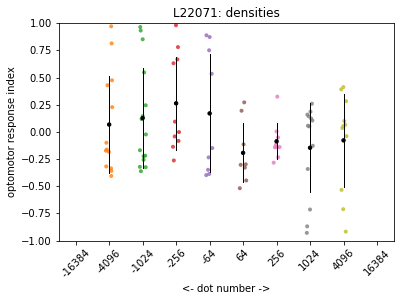

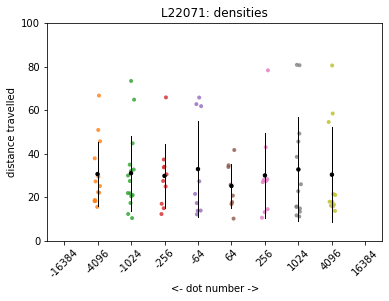

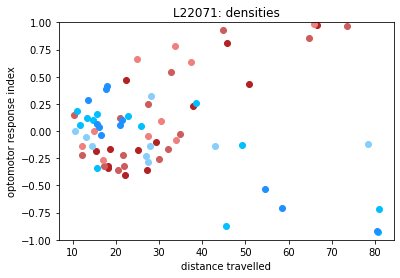

Z:/DATA/experiment_trackball_Optomotor/L22072/220908/densities


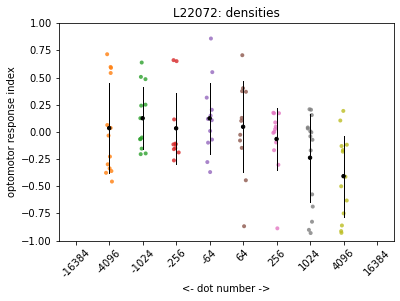

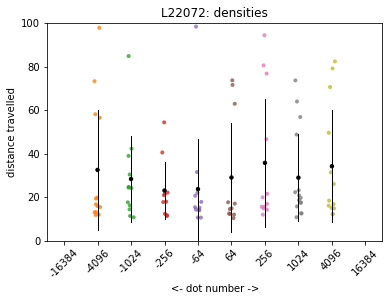

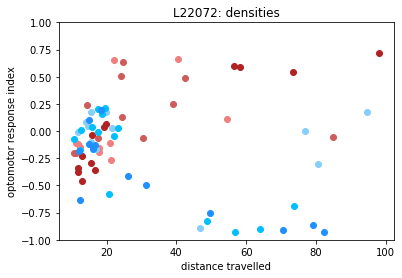

Z:/DATA/experiment_trackball_Optomotor/L22073/220908/densities


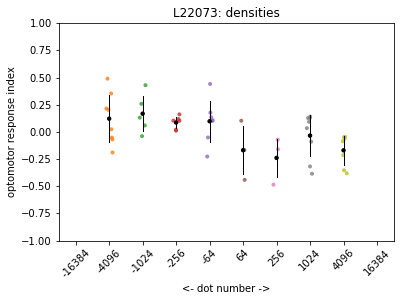

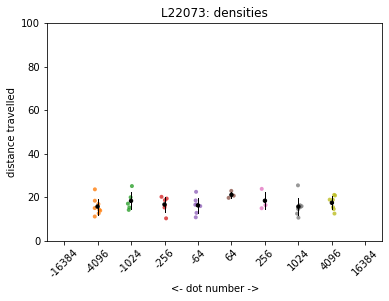

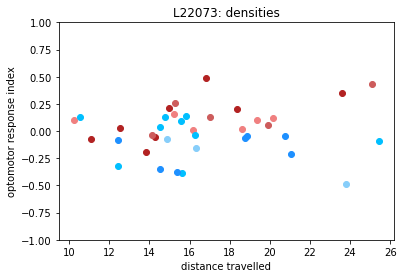

Z:/DATA/experiment_trackball_Optomotor/L22074/220908/densities


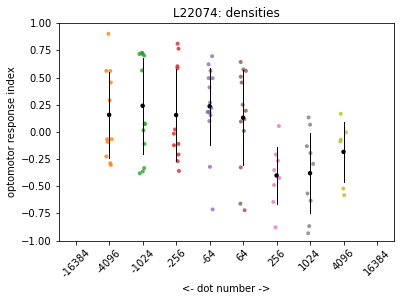

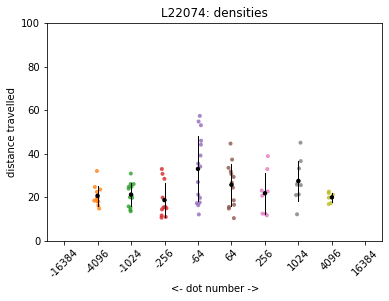

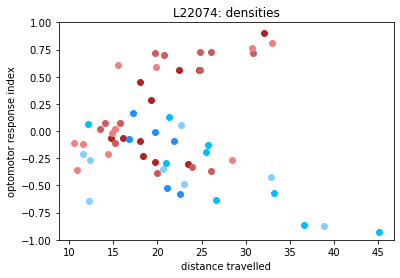

In [6]:
import os, fnmatch
import pandas as pd
import numpy as np
from scipy.signal import savgol_filter
import matplotlib.pyplot as plt
import seaborn as sns

savefigure = False
gettraj = False
getalldat = False

database_pattern='*.pickle'
frame_rate=144
sg_filering= True
averages = pd.DataFrame(np.zeros((1000,3)), columns = ['animal','stimulus', 'optomotor response index'])
averages[:] = np.nan
a=0

for thisDir in data_list:
    animal_name =thisDir.split('/')[3]
    file = os.listdir(thisDir)
    file_name= fnmatch.filter(file, database_pattern)
    if file_name==[]:
        print('skipped ' + thisDir)
        continue
    database= os.path.join(thisDir+'/',file_name[0])
    df=pd.read_pickle(database)

    df.loc[:,'grey_onset'] =False

    if sg_filering == True:
        df.loc[:, ['intergrated x position']] = savgol_filter(df.loc[:, ['intergrated x position']], 19, 3, axis=0)
        df.loc[:, ['intergrated y position']] = savgol_filter(df.loc[:, ['intergrated y position']], 19, 3, axis=0)
        
    if exp_name== 'splitcohdens' or exp_name== 'splitforward'or exp_name=='testlinks' or exp_name == 'testrechts' or exp_name=='splitlongfront' or exp_name=='splitscreen' or exp_name == 'splitcoh' or exp_name =='splitfront':
        stim_duration=60
        grey_duration=60
        stim_onset=np.where(df.loc[:,'stim_onset']==True)
        stim_onset = stim_onset + np.zeros(np.shape(stim_onset),dtype=int)
        grey_onset=stim_onset-np.ones(np.shape(stim_onset),dtype=int)*grey_duration*frame_rate
        stim_offset=stim_onset+np.ones(np.shape(stim_onset),dtype=int)*stim_duration*frame_rate
    else:
        stim_duration=25
        grey_duration=5
        stim_onset=np.where(df.loc[:,'stim_onset']==True)
        stim_onset = stim_onset + np.zeros(np.shape(stim_onset),dtype=int)
        grey_onset=stim_onset-np.ones(np.shape(stim_onset),dtype=int)*grey_duration*frame_rate
        stim_offset=stim_onset+np.ones(np.shape(stim_onset),dtype=int)*stim_duration*frame_rate

    analysis_window=frame_rate*(stim_duration+grey_duration)
   
#     stim_onset=np.where(df.loc[:,'stim_onset']==True)
    
#     grey_onset=stim_onset-np.zeros(np.shape(stim_onset),dtype=int)
#     stim_onset = stim_onset + np.ones(np.shape(stim_onset),dtype=int)*(stim_duration/2)*frame_rate
    
#     stim_offset=stim_onset+np.ones(np.shape(stim_onset),dtype=int)*(stim_duration/2-1)*frame_rate
#     df.stim_onset = False
    
    for ind in range(0,stim_onset.shape[1]):
        #data_of_interest[ind,:]=df.loc[grey_onset[0,ind]+1:stim_offset[0,ind],'delta rotation vector lab z']
        #df.loc[grey_onset[0,ind]:stim_offset[0,ind],'stim_variable'] = df.at[grey_onset[0,ind],'stim_variable']+ np.zeros([len(df.loc[grey_onset[0,ind]:stim_offset[0,ind],:]), 1])
        #df.loc[stim_onset[0,ind],'stim_onset']=True
        df.loc[grey_onset[0,ind], 'grey_onset']=True

        df.loc[stim_onset[0,ind]:stim_offset[0,ind],'event_num'] = int(ind+1)
        if exp_name== 'splitcohdens' or exp_name== 'splitforward'or exp_name=='testlinks' or exp_name == 'testrechts' or exp_name=='splitlongfront' or exp_name=='splitscreen' or exp_name == 'splitcoh' or exp_name=='splitfront':
            df.loc[grey_onset[0,ind]:(stim_onset[0,ind])-1, 'stimulus']= 'bar'
        else:
            df.loc[grey_onset[0,ind]:(stim_onset[0,ind])-1, 'stimulus']= 0
        df.loc[grey_onset[0,ind]:(stim_onset[0,ind])-1, 'event_num']= 'NaN'

        ev_dat = df.loc[stim_onset[0,ind]:stim_offset[0,ind]]
        bar_dat = df.loc[grey_onset[0,ind]:stim_onset[0,ind]-1]
        #ev_dat =ev_dat.loc[abs(df.anglechange)<5,:]
        ev_dat = ev_dat.reset_index()
        df.loc[stim_onset[0,ind]:stim_offset[0,ind],'distance travelled'] = distance_travelled(ev_dat)
        df.loc[stim_onset[0,ind]:stim_offset[0,ind],'optomotor response index'] = optomotor_response_idx(ev_dat.loc[: ,'delta rotation vector lab z'])

        #ev_dat =ev_dat.loc[abs(df.anglechange)<5,:]
        bar_dat = bar_dat.reset_index()
        df.loc[grey_onset[0,ind]:(stim_onset[0,ind])-1,'distance travelled'] = distance_travelled(bar_dat)
        df.loc[grey_onset[0,ind]:(stim_onset[0,ind])-1,'optomotor response index'] = optomotor_response_idx(bar_dat.loc[: ,'delta rotation vector lab z'])

        df.loc[stim_onset[0,ind]:stim_offset[0,ind],'optochange'] = df.loc[stim_onset[0,ind],'optomotor response index']-df.loc[grey_onset[0,ind],'optomotor response index']

        if gettraj == True:
            plt.plot(ev_dat.loc[:, 'intergrated x position'], ev_dat.loc[:,'intergrated y position'], 'red', label='stim: ' + str(np.round(df.loc[stim_onset[0,ind],'optomotor response index'], decimals= 3)))
            plt.plot(bar_dat.loc[:, 'intergrated x position'], bar_dat.loc[:,'intergrated y position'], 'blue', label='bar: ' + str(np.round(df.loc[grey_onset[0,ind],'optomotor response index'], decimals=3)))
            title = animal_name + '; ' + 'event '+ str(ind +1)+ '; '+ str(ev_dat.stim_variable[0][1]) + '-' + str(ev_dat.stim_variable[0][0])
            if (ev_dat.stim_variable[0][0]==256) & (ev_dat.stim_variable[0][1]==256) & (ev_dat.stim_variable[0][2]==ev_dat.stim_variable[0][3]):
                if ev_dat.stim_variable[0][2]<0:
                    title= title + ' right'
                elif ev_dat.stim_variable[0][2]>0:
                    title = title + ' left'

            if exp_name=='splitcohdens':
                if (ev_dat.stim_variable[0][0]==256) & (ev_dat.stim_variable[0][1]==256) & (ev_dat.stim_variable[0][3]!=ev_dat.stim_variable[0][4]):
                    if ev_dat.stim_variable[0][4]==20:
                        title= title + ' rightlowcoh'
                    elif ev_dat.stim_variable[0][5]==20:
                        title = title + ' leftlowcoh'
            plt.title(title)
            plt.legend(loc='upper right')

            if savefigure==True:
                figure_name= 'traj' + str(ind+1) + '.svg'
                directoryfig=os.path.join(thisDir,figure_name)
                plt.savefig(directoryfig)
           

            plt.show()
        
    df.event_num=df.event_num.astype('category')
    x = df.loc[df.stim_onset==True, :].reset_index()

    for i in range(0,len(x)):
        if exp_name == 'densities' :
            cond=x.stim_variable[i][3]*(x.stim_variable[i][5]/abs(x.stim_variable[i][5]))
            df.loc[df.event_num == x.loc[i, 'event_num'],'stimulus'] = cond * (-1)

        elif exp_name == 'gratings':
            df.loc[df.event_num == x.loc[i, 'event_num'],'stimulus'] = x.stim_variable[i][0]*(-1)

        elif exp_name == 'dots':
            cond=x.stim_variable[i][1]*(x.stim_variable[i][5]/abs(x.stim_variable[i][5]))
            df.loc[df.event_num == x.loc[i, 'event_num'],'stimulus'] = cond * (-1)


        elif exp_name =='splitscreen':
            conditions = [(x.stim_variable[i][0]==256) & (x.stim_variable[i][1]==256),
            (x.stim_variable[i][0]==256) & (x.stim_variable[i][1] ==64),
            (x.stim_variable[i][0]==256) & (x.stim_variable[i][1]==4096),
            (x.stim_variable[i][0]==64) & (x.stim_variable[i][1] == 256),
            (x.stim_variable[i][0] == 4096) & (x.stim_variable[i][1] == 256)]

            choices = ['equal', 'right low', 'right high', 'left low', 'left high']
            df.loc[df.event_num == x.loc[i, 'event_num'],'stimulus']=np.select(conditions, choices)

        elif exp_name =='splitforward'or exp_name=='testlinks' or exp_name == 'testrechts':
            conditions = [(x.stim_variable[i][0]==256) & (x.stim_variable[i][1]==256),
            (x.stim_variable[i][0]==256) & (x.stim_variable[i][1] ==64),
            (x.stim_variable[i][0]==256) & (x.stim_variable[i][1]==4096),
            (x.stim_variable[i][0]==64) & (x.stim_variable[i][1] == 256),
            (x.stim_variable[i][0] == 4096) & (x.stim_variable[i][1] == 256)]

            choices = ['equal', 'left low', 'left high', 'right low', 'right high']
            df.loc[df.event_num == x.loc[i, 'event_num'],'stimulus']=np.select(conditions, choices)

        elif exp_name =='splitcohdens':
            conditions = [(x.stim_variable[i][0]==256) & (x.stim_variable[i][1]==256) & (x.stim_variable[i][2]==-64) & (x.stim_variable[i][3]==64) & (x.stim_variable[i][4] == x.stim_variable[i][5]),
            (x.stim_variable[i][0]==256) & (x.stim_variable[i][1]==256) & (x.stim_variable[i][2]==-64) & (x.stim_variable[i][3]==-64),
            (x.stim_variable[i][0]==256) & (x.stim_variable[i][1]==256) & (x.stim_variable[i][2]==64) & (x.stim_variable[i][3]==64),
            (x.stim_variable[i][0]==256)  & (x.stim_variable[i][4]==20),
            (x.stim_variable[i][0]==256) & (x.stim_variable[i][1]==4096),
            (x.stim_variable[i][0]==256) & (x.stim_variable[i][5] == 20),
            (x.stim_variable[i][0] == 4096) & (x.stim_variable[i][1] == 256)]

            choices = ['equal', 'right', 'left', 'rightlowcoh', 'left high', 'leftlowcoh', 'right high']
            df.loc[df.event_num == x.loc[i, 'event_num'],'stimulus']=np.select(conditions, choices)

        elif exp_name =='splitlongfront':
            conditions = [(x.stim_variable[i][0]==256) & (x.stim_variable[i][1]==256) & (x.stim_variable[i][2]==-64) & (x.stim_variable[i][3]==64) ,
            (x.stim_variable[i][0]==256) & (x.stim_variable[i][1]==256) & (x.stim_variable[i][2]==-64) & (x.stim_variable[i][3]==-64),
            (x.stim_variable[i][0]==256) & (x.stim_variable[i][1]==256) & (x.stim_variable[i][2]==64) & (x.stim_variable[i][3]==64),
            (x.stim_variable[i][0]==256) & (x.stim_variable[i][1] ==64),
            (x.stim_variable[i][0]==256) & (x.stim_variable[i][1]==4096),
            (x.stim_variable[i][0]==64) & (x.stim_variable[i][1] == 256),
            (x.stim_variable[i][0] == 4096) & (x.stim_variable[i][1] == 256)]
 
            choices = ['equal', 'right', 'left', 'left low', 'left high', 'right low', 'right high']
            df.loc[df.event_num == x.loc[i, 'event_num'],'stimulus']=np.select(conditions, choices)
        
        elif exp_name =='splitfront':
            conditions = [(x.stim_variable[i][0]==256) & (x.stim_variable[i][1]==256),
            (x.stim_variable[i][0]==256) & (x.stim_variable[i][1] ==64),
            (x.stim_variable[i][0]==256) & (x.stim_variable[i][1]==4096),
             (x.stim_variable[i][0]==64) & (x.stim_variable[i][1] == 256),
            (x.stim_variable[i][0] == 4096) & (x.stim_variable[i][1] == 256)]

            choices = ['equal',  'left low', 'left high', 'right low', 'right high']
            df.loc[df.event_num == x.loc[i, 'event_num'],'stimulus']=np.select(conditions, choices)
        elif exp_name =='splitcoh':
            conditions = [(x.stim_variable[i][0]==50) & (x.stim_variable[i][1]==50),
            (x.stim_variable[i][0]==50) & (x.stim_variable[i][1] ==0),
            (x.stim_variable[i][0]==50) & (x.stim_variable[i][1]==100),
            (x.stim_variable[i][0]==0) & (x.stim_variable[i][1] == 50),
            (x.stim_variable[i][0] == 100) & (x.stim_variable[i][1] == 50)]

            choices = ['equal', 'right low', 'right high', 'left low', 'left high']
            df.loc[df.event_num == x.loc[i, 'event_num'],'stimulus']=np.select(conditions, choices)

  
    plot_dat= df.loc[(df.stim_onset==True) | (df.grey_onset==True), ['optomotor response index', 'optochange','stimulus', 'distance travelled', 'event_num']]

    print(thisDir)

    if exp_name == 'splitscreen' or exp_name == 'splitforward'or exp_name=='testlinks' or exp_name == 'testrechts':
        plot_dat.stimulus = plot_dat.stimulus.astype('category')
        sorter= ['bar','right high', 'left low', 'equal',  'right low', 'left high']
        plot_dat.stimulus = plot_dat.stimulus.cat.set_categories(sorter)
        plot_dat = plot_dat.sort_values(by=['stimulus'])
        plot_dat_all = plot_dat
        plot_dat = plot_dat.loc[plot_dat.loc[:, 'distance travelled']>20, :]

    elif exp_name == 'gratings' or exp_name== 'dots' or exp_name== 'densities':
        plot_dat= plot_dat.loc[plot_dat.stimulus != 0, :]
        plot_dat.stimulus = plot_dat.stimulus.astype('category')
        if exp_name=='densities':
            sorter= [-16384, -4096, -1024, -256,-64,64, 256, 1024, 4096, 16384]
        else:
            sorter= [-8, -4, -2, -1, 1,2,4,8]
        plot_dat.stimulus = plot_dat.stimulus.cat.set_categories(sorter)
        plot_dat = plot_dat.sort_values(by=['stimulus'])
        #sorter= [-8, -4, -2, -1, 1,2,4,8]
        #plot_dat.stimulus.astype('int')
        plot_dat_all = plot_dat
        plot_dat = plot_dat.loc[plot_dat.loc[:, 'distance travelled']>10, :]

    elif exp_name == 'splitlongfront' :
        plot_dat.stimulus = plot_dat.stimulus.astype('category')
        sorter= ['bar','left', 'left high', 'right low', 'equal',  'left low', 'right high', 'right']
        plot_dat.stimulus = plot_dat.stimulus.cat.set_categories(sorter)
        plot_dat = plot_dat.sort_values(by=['stimulus'])
        plot_dat_all = plot_dat
        plot_dat = plot_dat.loc[plot_dat.loc[:, 'distance travelled']>20, :]

    elif exp_name =='splitfront':
        plot_dat.stimulus = plot_dat.stimulus.astype('category')
        sorter= ['bar', 'left high', 'right low', 'equal',  'left low', 'right high']
        plot_dat.stimulus = plot_dat.stimulus.cat.set_categories(sorter)
        plot_dat = plot_dat.sort_values(by=['stimulus'])
        plot_dat_all = plot_dat
        plot_dat = plot_dat.loc[plot_dat.loc[:, 'distance travelled']>20, :]

    elif exp_name == 'splitcohdens':
        plot_dat.stimulus = plot_dat.stimulus.astype('category')
        sorter= ['bar','left', 'left high', 'rightlowcoh', 'equal',  'leftlowcoh', 'right high', 'right']
        plot_dat.stimulus = plot_dat.stimulus.cat.set_categories(sorter)
        plot_dat = plot_dat.sort_values(by=['stimulus'])
        plot_dat_all = plot_dat
        plot_dat = plot_dat.loc[plot_dat.loc[:, 'distance travelled']>20, :]

    elif exp_name == 'splitcoh':
        plot_dat.stimulus = plot_dat.stimulus.astype('category')
        sorter= ['right high', 'left low', 'equal',  'right low', 'left high']
        plot_dat.stimulus = plot_dat.stimulus.cat.set_categories(sorter)
        plot_dat = plot_dat.sort_values(by=['stimulus'])
        plot_dat_all = plot_dat
        plot_dat = plot_dat.loc[plot_dat.loc[:, 'distance travelled']>80, :]

    for i in plot_dat.stimulus.unique():
        averages.loc[a, 'animal']= animal_name
        averages.loc[a, 'stimulus']= i
        averages.loc[a, 'optomotor response index']= plot_dat.loc[plot_dat.stimulus==i, 'optomotor response index'].median()
        averages.loc[a, 'distance travelled']= plot_dat.loc[plot_dat.stimulus==i, 'distance travelled'].median()
        #             averages.loc[c, 'optobarnorm']=plot_dat.loc[plot_dat.stimulus==i, 'optomotor response index'].median() - plot_dat.loc[plot_dat.stimulus=='bar', 'optomotor response index'].median()
        #             averages.loc[c, 'optoequalnorm']=plot_dat.loc[plot_dat.stimulus==i, 'optomotor response index'].median() - plot_dat.loc[plot_dat.stimulus=='equal', 'optomotor response index'].median()
        #             averages.loc[c, 'optochange']= plot_dat.loc[plot_dat.stimulus==i, 'optochange'].median()
        a=a+1
                          
    if getalldat==True:
        plot_dat_all.loc[:, 'animal']=animal_name
        if thisDir== data_list[0]:
            allanimalevents = plot_dat_all
            print('test')
        else:
            allanimalevents= allanimalevents.append( plot_dat_all)

    ax =sns.stripplot(x="stimulus", y="optomotor response index", data=plot_dat, dodge=True, jitter=True, alpha=.8, zorder=1, size=4)
    ax =sns.pointplot(x="stimulus", y="optomotor response index", ci='sd', data=plot_dat, join=False, scale=0.5, zorder=100, color='black', errwidth=1)

    plt.xticks(rotation=45)
    plt.ylabel('optomotor response index')
    if exp_name== 'gratings':
        plt.xlabel('<- Hz ->')
        plt.xticks([0, 1,2, 3, 4, 5, 6, 7],[-8, -4, -2, -1, 1, 2, 4, 8])

        plt.title(animal_name + ': gratings')
    elif exp_name== 'dots':
        plt.xlabel('<- Dot Size ->')
        plt.xticks([0, 1,2, 3, 4, 5, 6, 7],['-8', '-4', '-2', '-1', '1', '2', '4', '8'])

        plt.title(animal_name + ': dots of different sizes')
    elif exp_name =='densities':
        thisDate = os.listdir(thisDir[0:45])
        plt.xlabel('<- dot number ->')
        #         if thisDate[0] in ['220824', '220825']:
        plt.xticks([0, 1,2, 3, 4, 5, 6, 7, 8, 9],['-16384', '-4096', '-1024', '-256','-64','64', '256', '1024', '4096', '16384'])
#         else:
#             plt.xticks([0, 1,2, 3, 4, 5, 6, 7],[ '4096', '1024', '256', '64', '64', '256', '1024', '4096'])

        plt.title(animal_name + ': densities')
    elif exp_name == 'splitforward':
        plt.title(animal_name + ': splitscreen with dots moving forward')
 
    elif exp_name == 'splitfront':
        plt.title(animal_name + ': splitscreen; only middle screen')

    elif exp_name == 'splitscreen':
        plt.title(animal_name + ': splitscreen')
        
    elif exp_name== 'splitlongfront':
        plt.title(animal_name + ': splitscreen')
       
    plt.ylim([-1, 1])
   
    
    

    if savefigure==True:
        figure_name= 'opto.svg'
        directoryfig=os.path.join(thisDir,figure_name)
        plt.savefig(directoryfig, bbox_inches='tight')
    plt.show()
    
#     ax =sns.stripplot(x="stimulus", y="optochange", data=plot_dat, dodge=True, jitter=True, alpha=.8, zorder=1, size=4)
#     ax =sns.pointplot(x="stimulus", y="optochange", ci='sd', data=plot_dat, join=False, scale=0.5, zorder=100, color='black', errwidth=1)
#     plt.title(thisDir )
#     plt.xticks(rotation=45)
#     plt.ylabel('optochange')
#     if exp_name== 'gratings' or exp_name=='dots':
#         plt.xlabel('<- Hz ->')
#         plt.xticks([0,1,2, 3, 4, 5, 6, 7],['8', '4', '2', '1', '1', '2', '4', '8'])
        
#     plt.ylim([-1, 1])
  
#     if savefigure==True:
#         figure_name= 'optochange.svg'
#         directoryfig=os.path.join(thisDir,figure_name)
#         plt.savefig(directoryfig, bbox_inches='tight')
#     plt.show()
   
    ax =sns.stripplot(x="stimulus", y="distance travelled", data=plot_dat, dodge=True, jitter=True, alpha=.8, zorder=1, size=4)
    ax =sns.pointplot(x="stimulus", y="distance travelled", ci='sd', data=plot_dat, join=False, scale=0.5, zorder=100, color='black', errwidth=1)

    if exp_name== 'gratings':
        plt.xlabel('<- Hz ->')
        plt.xticks([0, 1,2, 3, 4, 5, 6, 7],['8', '4', '2', '1', '1', '2', '4', '8'])
        plt.ylim([0, 50])
        plt.title(animal_name + ': gratings')
    elif exp_name=='dots':
        plt.xlabel('<- Dot Size ->')
        plt.xticks([0, 1,2, 3, 4, 5, 6, 7],['-8', '-4', '-2', '-1', '1', '2', '4', '8'])
        plt.ylim([0, 100])
        plt.title(animal_name + ': dots of differing size')
    elif exp_name =='densities':
        thisDate = os.listdir(thisDir[0:45])
        plt.xlabel('<- dot number ->')
#         if thisDate[0] in ['220824', '220825']:
        plt.xticks([0, 1,2, 3, 4, 5, 6, 7, 8, 9],['-16384', '-4096', '-1024', '-256','-64','64', '256', '1024', '4096', '16384'])
#         else:
#             plt.xticks([0, 1,2, 3, 4, 5, 6, 7],[ '4096', '1024', '256', '64', '64', '256', '1024', '4096'])
        plt.ylim([0, 100])
        plt.title(animal_name + ': densities')
    elif exp_name == 'splitforward':
        plt.title(animal_name + ': splitscreen with dots moving forward')
        plt.ylim([0, 300])
    elif exp_name == 'splitfront':
        plt.ylim([0, 200])
        plt.title(animal_name + ': splitscreen; only middle screen')
    elif exp_name == 'splitlongfront':
        plt.title(animal_name + ': splitscreen')
        plt.ylim([0, 200])
    elif exp_name == 'splitscreen':
        plt.ylim([0, 100])
        plt.title(animal_name + ': splitscreen')
    plt.xticks(rotation=45)
    plt.ylabel('distance travelled')

    #plt.ylim([0, 250])
    # ax.set_xticklabels([ '4096', '1024', '256','64', '64', '256', '1024', '4096'])
    # # plt.xticks()
    #plt.savefig('optomotor_80.svg')
    if savefigure==True:
        figure_name= 'dist.svg'
        directoryfig=os.path.join(thisDir,figure_name)
        plt.savefig(directoryfig, bbox_inches='tight')
    plt.show()

    if exp_name=='dots' or exp_name=='gratings':
        s1=plt.scatter(plot_dat.loc[plot_dat.stimulus== 1, 'distance travelled'], plot_dat.loc[plot_dat.stimulus== 1, 'optomotor response index'], c='lightskyblue')
        s2=plt.scatter(plot_dat.loc[plot_dat.stimulus== 2, 'distance travelled'], plot_dat.loc[plot_dat.stimulus== 2, 'optomotor response index'], c='deepskyblue')
        s3=plt.scatter(plot_dat.loc[plot_dat.stimulus== 4, 'distance travelled'], plot_dat.loc[plot_dat.stimulus== 4, 'optomotor response index'], c='dodgerblue')
        s4=plt.scatter(plot_dat.loc[plot_dat.stimulus== 8, 'distance travelled'], plot_dat.loc[plot_dat.stimulus== 8, 'optomotor response index'], c='royalblue')
        s5=plt.scatter(plot_dat.loc[plot_dat.stimulus== -1, 'distance travelled'], plot_dat.loc[plot_dat.stimulus== -1, 'optomotor response index'], c='lightcoral')
        s6=plt.scatter(plot_dat.loc[plot_dat.stimulus== -2, 'distance travelled'], plot_dat.loc[plot_dat.stimulus== -2, 'optomotor response index'], c='indianred')
        s7=plt.scatter(plot_dat.loc[plot_dat.stimulus== -4, 'distance travelled'], plot_dat.loc[plot_dat.stimulus== -4, 'optomotor response index'], c='firebrick')
        s8=plt.scatter(plot_dat.loc[plot_dat.stimulus== -8, 'distance travelled'], plot_dat.loc[plot_dat.stimulus== -8, 'optomotor response index'], c='maroon')
        plt.ylim([-1, 1])
        plt.xlim([0, 80])
        plt.xlabel('distance travelled')
        plt.ylabel('optomotor response index')
        plt.legend([s1, s2, s3, s4, s5, s6, s7, s8], [1, 2, 4, 8, -1, -2, -4, -8],loc='best')
        if exp_name=='dots':
            plt.title(animal_name + ': dots of differing size')
        else:
            plt.title(animal_name + ': gratings')
        if savefigure==True:
            figure_name= 'distopto.svg'
            directoryfig=os.path.join(thisDir,figure_name)
            plt.savefig(directoryfig, bbox_inches='tight')
        plt.show()

    if exp_name=='densities':
        stimuli= [-16384, -4096, -1024, -256, 256, 1024, 4096, 16384]
        c=0
        colors = ['maroon', 'firebrick', 'indianred', 'lightcoral','lightskyblue', 'deepskyblue', 'dodgerblue', 'royalblue']
        for i in stimuli:
            plt.scatter(plot_dat.loc[plot_dat.stimulus== i, 'distance travelled'], plot_dat.loc[plot_dat.stimulus== i, 'optomotor response index'], c=colors[c])
            c=c+1
        plt.ylim([-1, 1])
        plt.xlabel('distance travelled')
        plt.ylabel('optomotor response index')
        plt.title(animal_name + ': densities')
        if savefigure==True:
            figure_name= 'distopto.svg'
            directoryfig=os.path.join(thisDir,figure_name)
            plt.savefig(directoryfig, bbox_inches='tight')
        plt.show()
    if exp_name=='splitforward' or exp_name=='splitscreen':
        stimuli= sorter
        c=0
        colors = ['black', 'firebrick', 'indianred', 'green', 'deepskyblue', 'dodgerblue']
        for i in stimuli:
            plt.scatter(plot_dat.loc[plot_dat.stimulus== i, 'distance travelled'], plot_dat.loc[plot_dat.stimulus== i, 'optomotor response index'], c=colors[c])
            c=c+1
        plt.ylim([-1, 1])
        plt.xlim([0,300])
        plt.xlabel('distance travelled')
        plt.ylabel('optomotor response index')
        if exp_name=='splitforward':
            plt.title(animal_name + ': splitscreen with dots moving forward')
        else:
            plt.title(animal_name + ': splitscreen')
        if savefigure==True:
            figure_name= 'distopto.svg'
            directoryfig=os.path.join(thisDir,figure_name)
            plt.savefig(directoryfig, bbox_inches='tight')
        plt.show()
    if exp_name=='splitfront' or exp_name=='splitlongfront':
        stimuli= sorter
        c=0
        colors = ['black','maroon', 'firebrick', 'indianred', 'green', 'deepskyblue', 'dodgerblue', 'royalblue']
        for i in stimuli:
            plt.scatter(plot_dat.loc[plot_dat.stimulus== i, 'distance travelled'], plot_dat.loc[plot_dat.stimulus== i, 'optomotor response index'], c=colors[c])
            c=c+1
        plt.ylim([-1, 1])
        plt.xlabel('distance travelled')
        plt.ylabel('optomotor response index')
        if exp_name== 'splitfront':
            plt.title(animal_name + ': splitscreen; only middle screen')
        elif exp_name=='splitlongfront':
            plt.title(animal_name + ': splitscreen')
        if savefigure==True:
            figure_name= 'distopto.svg'
            directoryfig=os.path.join(thisDir,figure_name)
            plt.savefig(directoryfig, bbox_inches='tight')
        plt.show()

FileNotFoundError: [WinError 3] Das System kann den angegebenen Pfad nicht finden: 'C:/Users/excid/Documents/University/Master/An'

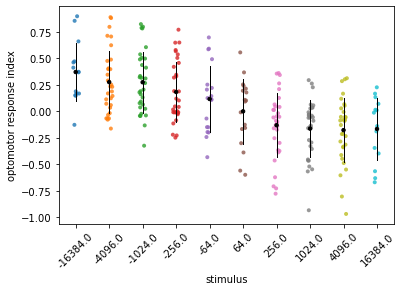

In [14]:
savefigure=False
plot_dat=averages
#exp_name='splitlongfront_soli'
thisDir='C:/Users/excid/Documents/University/Master/Analysis/trackball/' + exp_name + '/'
#exp_name='splitlongfront'
#for s in sorter:
    #thisStim = allanimalevents.loc[allanimalevents.stimulus==s, :]
    #thisStim.to_csv(thisDir+ str(s) +'.csv')

ax =sns.stripplot(x="stimulus", y="optomotor response index", data=plot_dat, dodge=True, jitter=True, alpha=.8, zorder=1, size=4)
ax =sns.pointplot(x="stimulus", y="optomotor response index", ci='sd', data=plot_dat, join=False, scale=0.5, zorder=100, color='black', errwidth=1)

plt.xticks(rotation=45)
plt.ylabel('optomotor response index')
if exp_name== 'gratings':
    plt.xlabel('<- Hz ->')
    plt.xticks([0, 1,2, 3, 4, 5, 6, 7],[-8, -4, -2, -1, 1, 2, 4, 8])

    plt.title('gratings')
elif exp_name== 'dots':
    plt.xlabel('<- Dot Size ->')
    plt.xticks([0, 1,2, 3, 4, 5, 6, 7],['-8', '-4', '-2', '-1', '1', '2', '4', '8'])

    plt.title(animal_name + ': dots of different sizes')
elif exp_name =='densities':
    thisDate = os.listdir(thisDir[0:45])
    plt.xlabel('<- dot number ->')
    #         if thisDate[0] in ['220824', '220825']:
    plt.xticks([0, 1,2, 3, 4, 5, 6, 7, 8, 9],['-16384', '-4096', '-1024', '-256','-64','64', '256', '1024', '4096', '16384'])
#         else:
#             plt.xticks([0, 1,2, 3, 4, 5, 6, 7],[ '4096', '1024', '256', '64', '64', '256', '1024', '4096'])

    plt.title('densities')
    
elif exp_name == 'splitforward':
    plt.title('splitscreen with dots moving forward')

elif exp_name == 'splitfront':
    plt.title('splitscreen; only middle screen')

elif exp_name == 'splitscreen':
    plt.title('splitscreen')
    
elif exp_name=='splitlongfront':
        plt.title('splitscreen')
    
plt.ylim([-1, 1])

if savefigure==True:
    figure_name= 'opto.svg'
    directoryfig=os.path.join(thisDir,figure_name)
    plt.savefig(directoryfig, bbox_inches='tight')
plt.show()

ax =sns.stripplot(x="stimulus", y="distance travelled", data=plot_dat, dodge=True, jitter=True, alpha=.8, zorder=1, size=4)
ax =sns.pointplot(x="stimulus", y="distance travelled", ci='sd', data=plot_dat, join=False, scale=0.5, zorder=100, color='black', errwidth=1)

if exp_name== 'gratings':
    plt.xlabel('<- Hz ->')
    plt.xticks([0, 1,2, 3, 4, 5, 6, 7],['8', '4', '2', '1', '1', '2', '4', '8'])
    plt.ylim([0, 50])
    plt.title('gratings')
elif exp_name=='dots':
    plt.xlabel('<- Dot Size ->')
    plt.xticks([0, 1,2, 3, 4, 5, 6, 7],['-8', '-4', '-2', '-1', '1', '2', '4', '8'])
    plt.ylim([0, 100])
    plt.title('dots of differing size')
elif exp_name =='densities':
    thisDate = os.listdir(thisDir[0:45])
    plt.xlabel('<- dot number ->')
#         if thisDate[0] in ['220824', '220825']:
    plt.xticks([0, 1,2, 3, 4, 5, 6, 7, 8, 9],['-16384', '-4096', '-1024', '-256','-64','64', '256', '1024', '4096', '16384'])
#         else:
#             plt.xticks([0, 1,2, 3, 4, 5, 6, 7],[ '4096', '1024', '256', '64', '64', '256', '1024', '4096'])
    plt.ylim([0, 100])
    plt.title('densities')
elif exp_name == 'splitforward':
    plt.title('splitscreen with dots moving forward')
    plt.ylim([0, 300])
elif exp_name == 'splitfront':
    plt.ylim([0, 200])
    plt.title('splitscreen; only middle screen')
elif exp_name == 'splitscreen':
    plt.ylim([0, 100])
    plt.title('splitscreen')
elif exp_name=='splitlongfront':
        plt.title('splitscreen')
plt.xticks(rotation=45)
plt.ylabel('distance travelled')

#plt.ylim([0, 250])
# ax.set_xticklabels([ '4096', '1024', '256','64', '64', '256', '1024', '4096'])
# # plt.xticks()
#plt.savefig('optomotor_80.svg')
if savefigure==True:
    figure_name= 'dist.svg'
    directoryfig=os.path.join(thisDir,figure_name)
    plt.savefig(directoryfig, bbox_inches='tight')
plt.show()

if exp_name=='dots' or exp_name=='gratings':
    s1=plt.scatter(plot_dat.loc[plot_dat.stimulus== 1, 'distance travelled'], plot_dat.loc[plot_dat.stimulus== 1, 'optomotor response index'], c='lightskyblue')
    s2=plt.scatter(plot_dat.loc[plot_dat.stimulus== 2, 'distance travelled'], plot_dat.loc[plot_dat.stimulus== 2, 'optomotor response index'], c='deepskyblue')
    s3=plt.scatter(plot_dat.loc[plot_dat.stimulus== 4, 'distance travelled'], plot_dat.loc[plot_dat.stimulus== 4, 'optomotor response index'], c='dodgerblue')
    s4=plt.scatter(plot_dat.loc[plot_dat.stimulus== 8, 'distance travelled'], plot_dat.loc[plot_dat.stimulus== 8, 'optomotor response index'], c='royalblue')
    s5=plt.scatter(plot_dat.loc[plot_dat.stimulus== -1, 'distance travelled'], plot_dat.loc[plot_dat.stimulus== -1, 'optomotor response index'], c='lightcoral')
    s6=plt.scatter(plot_dat.loc[plot_dat.stimulus== -2, 'distance travelled'], plot_dat.loc[plot_dat.stimulus== -2, 'optomotor response index'], c='indianred')
    s7=plt.scatter(plot_dat.loc[plot_dat.stimulus== -4, 'distance travelled'], plot_dat.loc[plot_dat.stimulus== -4, 'optomotor response index'], c='firebrick')
    s8=plt.scatter(plot_dat.loc[plot_dat.stimulus== -8, 'distance travelled'], plot_dat.loc[plot_dat.stimulus== -8, 'optomotor response index'], c='maroon')
    plt.ylim([-1, 1])
    plt.xlim([0, 80])
    plt.xlabel('distance travelled')
    plt.ylabel('optomotor response index')
    plt.legend([s1, s2, s3, s4, s5, s6, s7, s8], [1, 2, 4, 8, -1, -2, -4, -8],loc='best')
    if exp_name=='dots':
        plt.title('dots of differing size')
        
    else:
        plt.title('gratings')
    if savefigure==True:
        figure_name= 'distopto.svg'
        directoryfig=os.path.join(thisDir,figure_name)
        plt.savefig(directoryfig, bbox_inches='tight')
    plt.show()

if exp_name=='densities':
    stimuli= [-16384, -4096, -1024, -256, 256, 1024, 4096, 16384]
    c=0
    colors = ['maroon', 'firebrick', 'indianred', 'lightcoral','lightskyblue', 'deepskyblue', 'dodgerblue', 'royalblue']
    for i in stimuli:
        plt.scatter(plot_dat.loc[plot_dat.stimulus== i, 'distance travelled'], plot_dat.loc[plot_dat.stimulus== i, 'optomotor response index'], c=colors[c])
        c=c+1
    plt.ylim([-1, 1])
    plt.xlabel('distance travelled')
    plt.ylabel('optomotor response index')
    plt.title('densities')
    if savefigure==True:
        figure_name= 'distopto.svg'
        directoryfig=os.path.join(thisDir,figure_name)
        plt.savefig(directoryfig, bbox_inches='tight')
    plt.show()
if exp_name=='splitforward' or exp_name=='splitscreen':
    stimuli= sorter
    c=0
    colors = ['black', 'firebrick', 'indianred', 'green', 'deepskyblue', 'dodgerblue']
    for i in stimuli:
        plt.scatter(plot_dat.loc[plot_dat.stimulus== i, 'distance travelled'], plot_dat.loc[plot_dat.stimulus== i, 'optomotor response index'], c=colors[c])
        c=c+1
    plt.ylim([-1, 1])
    plt.xlim([0,300])
    plt.xlabel('distance travelled')
    plt.ylabel('optomotor response index')
    if exp_name=='splitforward':
        plt.title('splitscreen with dots moving forward')
    else:
        plt.title('splitscreen')
    if savefigure==True:
        figure_name= 'distopto.svg'
        directoryfig=os.path.join(thisDir,figure_name)
        plt.savefig(directoryfig, bbox_inches='tight')
    plt.show()
if exp_name=='splitfront' or exp_name=='splitlongfront':
    stimuli= sorter
    c=0
    colors = ['black','maroon', 'firebrick', 'indianred', 'green', 'deepskyblue', 'dodgerblue', 'royalblue']
    for i in stimuli:
        plt.scatter(plot_dat.loc[plot_dat.stimulus== i, 'distance travelled'], plot_dat.loc[plot_dat.stimulus== i, 'optomotor response index'], c=colors[c])
        c=c+1
    plt.ylim([-1, 1])
    plt.xlabel('distance travelled')
    plt.ylabel('optomotor response index')
    if exp_name== 'splitfront':
        plt.title('splitscreen; only middle screen')
    elif exp_name=='splitlongfront':
        plt.title('splitscreen')
    if savefigure==True:
        figure_name= 'distopto.svg'
        directoryfig=os.path.join(thisDir,figure_name)
        plt.savefig(directoryfig, bbox_inches='tight')
    plt.show()

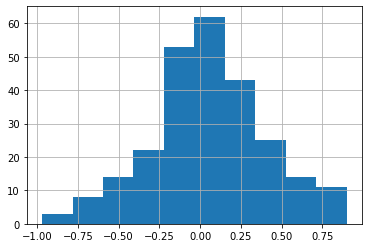

<AxesSubplot:xlabel='Theoretical quantiles', ylabel='Ordered quantiles'>

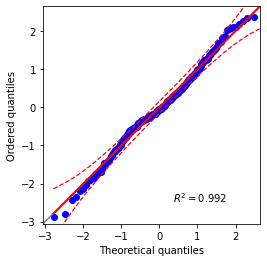

In [17]:
#Test assumption of normality
import numpy as np
import pingouin as pg

averages.loc[:,'optomotor response index'].hist()
plt.show()



pg.qqplot(averages.loc[:,'optomotor response index'])


In [ ]:
#test assumption of 

In [9]:
averages

,animal,stimulus,optomotor response index,distance travelled
0,L22001,-8.0,0.015975,15.847384
1,L22001,-4.0,0.070314,17.497657
2,L22001,-2.0,0.009909,14.134638
3,L22001,-1.0,0.008907,18.399479
4,L22001,1.0,-0.265721,16.997158
...,...,...,...,...
995,NaN,NaN,NaN,NaN
996,NaN,NaN,NaN,NaN
997,NaN,NaN,NaN,NaN
998,NaN,NaN,NaN,NaN


In [7]:
test=averages.loc[averages.animal.notna() == True ,:]
test=test.loc[test.stimulus.notna() == True ,:]

In [10]:
test

,animal,stimulus,optomotor response index,distance travelled
0,L22036,-16384.0,0.854631,25.452695
1,L22036,-4096.0,0.291304,20.409455
2,L22036,-1024.0,0.788252,40.749134
3,L22036,-256.0,0.318844,15.319657
4,L22036,256.0,-0.297883,23.500354
...,...,...,...,...
251,L22074,-64.0,0.221085,34.078426
252,L22074,64.0,0.194653,26.603939
253,L22074,256.0,-0.387032,21.635177
254,L22074,1024.0,-0.293833,25.773548


In [11]:
animallowdens= test.loc[test.stimulus==-64, 'animal'].unique()

In [67]:
animalbigdots 

array(['L22036', 'L22037', 'L22038', 'L22039', 'L22040', 'L22041',
       'L22043', 'L22044', 'L22045', 'L22046', 'L22049', 'L22050',
       'L22051', 'L22052'], dtype=object)

In [12]:
c=0
for animal in animallowdens:
    curr_animal=test.loc[test.animal==animal, :]
    if len(curr_animal)!= 8:
        print(animal)
        print(curr_animal)
        continue
    if c==0:
        testlowdens= curr_animal
        c=1
    else:
        testlowdens= testlowdens.append(curr_animal)

In [14]:
test=testlowdens
stimuli=test.stimulus.unique()
stimuli

array([-4096., -1024.,  -256.,   -64.,    64.,   256.,  1024.,  4096.])

In [15]:
import pingouin as pg

pg.sphericity(data= test, dv= 'optomotor response index', within= 'stimulus', subject='animal')

SpherResults(spher=False, W=0.0008451688023900902, chi2=102.26467452238708, dof=27, pval=2.401190250622634e-10)

In [137]:
test=test.sort_values('stimulus')

In [9]:
import pingouin as pg

dots_friedman=pg.friedman(data= test, dv= 'optomotor response index', within= 'stimulus', subject='animal')

C:\Users\excid\anaconda3\lib\site-packages\pingouin\nonparametric.py:715: RuntimeWarning: invalid value encountered in double_scalars
  W = (12 * ssbn - 3 * n**2 * k * (k + 1) ** 2) / (n**2 * k * (k - 1) * (k + 1) - n * ties)


In [164]:
import scikit_posthocs as sp

sp.posthoc_nemenyi_friedman(a=test, y_col='optomotor response index', group_col='stimulus', block_col= 'animal', melted=True)

,-8.0,-4.0,-2.0,2.0,4.0,8.0
-8.0,1.000000,0.900000,0.900000,0.021524,0.184370,0.497558
-4.0,0.900000,1.000000,0.900000,0.033952,0.249219,0.583265
-2.0,0.900000,0.900000,1.000000,0.007281,0.086578,0.300912
2.0,0.021524,0.033952,0.007281,1.000000,0.900000,0.711617
4.0,0.184370,0.249219,0.086578,0.900000,1.000000,0.900000
8.0,0.497558,0.583265,0.300912,0.711617,0.900000,1.000000


In [157]:
import pingouin as pg

pg.friedman(data= test, dv= 'distance travelled', within= 'stimulus', subject='animal')

,Source,W,ddof1,Q,p-unc
Friedman,stimulus,0.03254,5,1.952381,0.855694


In [143]:
print(dots_small_friedman.to_latex())

\begin{tabular}{llrrrr}
\toprule
{} &    Source &         W &  ddof1 &          Q &         p-unc \\
\midrule
Friedman &  stimulus &  0.600945 &      7 &  46.272727 &  7.736111e-08 \\
\bottomrule
\end{tabular}



In [145]:
print(dots_small_posthoc.to_latex())

\begin{tabular}{lrrrrrrrr}
\toprule
{} &      -8.0 &          -4.0 &      -2.0 &      -1.0 &       1.0 &       2.0 &           4.0 &           8.0 \\
\midrule
-8.0 &  1.000000 &  1.000000e+00 &  1.000000 &  1.000000 &  0.300519 &  0.000695 &  1.866907e-05 &  4.654402e-05 \\
-4.0 &  1.000000 &  1.000000e+00 &  1.000000 &  1.000000 &  0.018161 &  0.000012 &  1.907933e-07 &  5.497268e-07 \\
-2.0 &  1.000000 &  1.000000e+00 &  1.000000 &  1.000000 &  0.300519 &  0.000695 &  1.866907e-05 &  4.654402e-05 \\
-1.0 &  1.000000 &  1.000000e+00 &  1.000000 &  1.000000 &  0.098040 &  0.000112 &  2.646468e-06 &  7.262738e-06 \\
 1.0 &  0.300519 &  1.816104e-02 &  0.300519 &  0.098040 &  1.000000 &  0.444362 &  5.223528e-02 &  9.804044e-02 \\
 2.0 &  0.000695 &  1.168664e-05 &  0.000695 &  0.000112 &  0.444362 &  1.000000 &  1.000000e+00 &  1.000000e+00 \\
 4.0 &  0.000019 &  1.907933e-07 &  0.000019 &  0.000003 &  0.052235 &  1.000000 &  1.000000e+00 &  1.000000e+00 \\
 8.0 &  0.000047 &  5.497268e

In [ ]:
from scipy import stats
[H,p]=stats.kruskal(test.loc[test.stimulus==stimuli[0], 'optomotor response index'], 
              test.loc[test.stimulus==stimuli[1], 'optomotor response index'],
              test.loc[test.stimulus==stimuli[2], 'optomotor response index'], 
              test.loc[test.stimulus==stimuli[3], 'optomotor response index'],
              test.loc[test.stimulus==stimuli[4], 'optomotor response index'], 
              test.loc[test.stimulus==stimuli[5], 'optomotor response index'], 
              test.loc[test.stimulus==stimuli[6], 'optomotor response index'],
              test.loc[test.stimulus==stimuli[7], 'optomotor response index'],
              test.loc[test.stimulus==stimuli[9], 'optomotor response index'],
              test.loc[test.stimulus==stimuli[10], 'optomotor response index'])

print(p)

In [112]:
epsilonsquare=H * ((len(test)+1)/((len(test)**2)-1))
print(epsilonsquare)

0.3196407416441433


In [ ]:
import scikit_posthocs as sp
sp.posthoc_wilcoxon(test, val_col='optomotor response index', group_col= 'stimulus', p_adjust = 'bonferroni')

In [113]:
import scikit_posthocs as sp
sp.posthoc_dunn(test, val_col='optomotor response index', group_col= 'stimulus', p_adjust = 'bonferroni')


,1,2,3,4,5,6,7,8,9,10
1,1.000000,1.000000,1.000000,1.000000,0.000318,0.000051,0.000048,0.003734,1.000000,0.201306
2,1.000000,1.000000,1.000000,1.000000,0.000237,0.000021,0.000021,0.009565,1.000000,0.703475
3,1.000000,1.000000,1.000000,1.000000,0.000136,0.000012,0.000011,0.006684,1.000000,0.535394
4,1.000000,1.000000,1.000000,1.000000,0.020564,0.003023,0.002850,0.176063,1.000000,1.000000
5,0.000318,0.000237,0.000136,0.020564,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
6,0.000051,0.000021,0.000012,0.003023,1.000000,1.000000,1.000000,1.000000,0.367533,1.000000
7,0.000048,0.000021,0.000011,0.002850,1.000000,1.000000,1.000000,1.000000,0.342676,1.000000
8,0.003734,0.009565,0.006684,0.176063,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
9,1.000000,1.000000,1.000000,1.000000,1.000000,0.367533,0.342676,1.000000,1.000000,1.000000
10,0.201306,0.703475,0.535394,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [118]:
sp.posthoc_dunn(test, val_col='optomotor response index', group_col= 'stimulus', p_adjust = 'bonferroni')

,-16384.0,-4096.0,-1024.0,-256.0,-64.0,64.0,256.0,1024.0,4096.0,16384.0
-16384.0,1.000000,1.000000,1.000000,1.000000,1.000000,0.201306,0.000318,0.000051,0.000048,0.003734
-4096.0,1.000000,1.000000,1.000000,1.000000,1.000000,0.703475,0.000237,0.000021,0.000021,0.009565
-1024.0,1.000000,1.000000,1.000000,1.000000,1.000000,0.535394,0.000136,0.000012,0.000011,0.006684
-256.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.020564,0.003023,0.002850,0.176063
-64.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.367533,0.342676,1.000000
64.0,0.201306,0.703475,0.535394,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
256.0,0.000318,0.000237,0.000136,0.020564,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1024.0,0.000051,0.000021,0.000012,0.003023,0.367533,1.000000,1.000000,1.000000,1.000000,1.000000
4096.0,0.000048,0.000021,0.000011,0.002850,0.342676,1.000000,1.000000,1.000000,1.000000,1.000000
16384.0,0.003734,0.009565,0.006684,0.176063,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [94]:
from scipy import stats

test=averages.loc[averages.animal.notna() == True ,:]

[H,p]=stats.kruskal(test.loc[test.stimulus==stimuli[0], 'distance travelled'], 
              test.loc[test.stimulus==stimuli[1], 'distance travelled'],
              test.loc[test.stimulus==stimuli[2], 'distance travelled'], 
              test.loc[test.stimulus==stimuli[3], 'distance travelled'],
              test.loc[test.stimulus==stimuli[4], 'distance travelled'], 
              test.loc[test.stimulus==stimuli[5], 'distance travelled'], 
              test.loc[test.stimulus==stimuli[6], 'distance travelled'],
              test.loc[test.stimulus==stimuli[7], 'distance travelled'])

print(p)

0.9765086057678286


In [35]:
import scikit_posthocs as sp
data=[test.loc[test.stimulus=='bar', 'optomotor response index'], 
test.loc[test.stimulus=='left', 'optomotor response index'],
test.loc[test.stimulus=='left high', 'optomotor response index'],
test.loc[test.stimulus=='right low', 'optomotor response index'],
test.loc[test.stimulus=='equal', 'optomotor response index'],
test.loc[test.stimulus=='left low', 'optomotor response index'],
test.loc[test.stimulus=='right high', 'optomotor response index'],
test.loc[test.stimulus=='right', 'optomotor response index']]
            
sp.posthoc_dunn(data, p_adjust = 'bonferroni')



,1,2,3,4,5,6,7,8
1,1.000000,0.645251,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
2,0.645251,1.000000,1.000000,1.000000,1.000000,1.000000,0.158700,0.000638
3,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.128711
4,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.585775,0.004296
5,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.280704
6,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.875061
7,1.000000,0.158700,1.000000,0.585775,1.000000,1.000000,1.000000,1.000000
8,1.000000,0.000638,0.128711,0.004296,0.280704,0.875061,1.000000,1.000000


In [36]:
data

[0      0.113444
 8      0.317601
 16    -0.452366
 24    -0.420388
 32     0.624569
 39     0.033112
 47    -0.010476
 55    -0.079274
 63    -0.699796
 71    -0.205845
 79    -0.133920
 86    -0.066611
 94     0.627429
 102    0.280092
 110    0.015783
 118    0.642658
 126    0.031124
 134   -0.051748
 Name: optomotor response index, dtype: float64,
 1      0.797028
 9      0.889384
 17    -0.096068
 25     0.627482
 33     0.979653
 40     0.229349
 48     0.220020
 56     0.040623
 64    -0.373907
 72     0.012654
 80     0.324485
 87     0.035835
 95     0.836058
 103    0.800943
 111    0.052179
 119    0.922098
 127    0.591640
 135   -0.056947
 Name: optomotor response index, dtype: float64,
 2      0.396082
 10     0.723734
 18     0.047471
 26     0.939378
 41     0.324353
 49     0.194111
 57    -0.519399
 65    -0.845679
 73    -0.236650
 81     0.304320
 88    -0.111549
 96     0.607823
 104    0.227676
 112   -0.006128
 120   -0.274710
 128    0.549227
 136    0.221481
 

In [4]:

def optomotor_response_idx(ev_dat):
    opt_idx =(np.nansum(abs(ev_dat.loc[ev_dat<0]))- np.nansum(abs(ev_dat.loc[ev_dat>0])))/(np.nansum(abs(ev_dat.loc[ev_dat<0]))+ np.nansum(abs(ev_dat.loc[ev_dat>0])))
    return opt_idx

In [5]:
def distance_travelled(curr_data):
        diff_dat = curr_data.loc[:, ['intergrated x position', 'intergrated y position']].diff()
        dist= np.sqrt(diff_dat.loc[:,'intergrated x position'].pow(2) + diff_dat.loc[:,'intergrated y position'].pow(2))
        distr = np.nansum(dist)
        return distr

In [239]:
def distance(curr_data):
        diff_dat = curr_data.loc[:, ['intergrated x position', 'intergrated y position']].diff(5)
        dist= np.sqrt(diff_dat.loc[:,'intergrated x position'].pow(2) + diff_dat.loc[:,'intergrated y position'].pow(2))
        dist=np.array(dist)
        return dist

In [194]:
def angle(curr_data):
        diff_dat = curr_data.loc[:, ['intergrated x position', 'intergrated y position']].diff()
        angles=np.arctan2(diff_dat.loc[:, 'intergrated y position'], diff_dat.loc[:,'intergrated x position'])
        turn = angles.diff()
        turn= np.array(turn)
        return turn